# 3. The pipeline: gene selection and the graph model under nested cross-validation

Question: does a graph model on genes selected inside each training part predict overall survival better than the clinical covariates alone?

What enters: the cohort tables of notebook 1 and the STRING edge lists of notebook 2.

What leaves: fold files, comparison rows, training curves, frozen final models, METABRIC scores and tables in `results/03_pipeline/`; the first run stays in `first_run/`.

Result: rendered under the imports from the saved summary.

How to run: the nbconvert command of notebook 1; seconds in read mode, hours in compute mode.

In [1]:
import hashlib
import json
import os
import subprocess
import sys
import time
import warnings
from importlib.metadata import version
from pathlib import Path

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")  # deterministic GPU matrix products
warnings.simplefilter("ignore", FutureWarning)  # torch's import-time notice about torch.jit
warnings.filterwarnings("ignore", module="tqdm")  # tqdm asks for a widget the notebook lacks
warnings.filterwarnings("ignore", message="Ties in `time`")  # the Breslow choice, repeated per fit

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from scipy import stats
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sksurv.linear_model import CoxnetSurvivalAnalysis, CoxPHSurvivalAnalysis
from sksurv.metrics import concordance_index_censored, concordance_index_ipcw
from sksurv.util import Surv
from torch_geometric.data import Batch, Data
from torch_geometric.nn import GATv2Conv, GCNConv, GINConv, SAGEConv, global_mean_pool
from torchsurv.loss.cox import neg_partial_log_likelihood

warnings.simplefilter("error", ConvergenceWarning)  # a selector path that does not converge stops

In [2]:
summary_file = Path("../results/03_pipeline/summary.csv")
if summary_file.exists():
    saved = pd.read_csv(summary_file, index_col=0)["value"]
    display(Markdown(f"Result: over {saved['outer folds done']} of 5 outer folds the graph model "
                     f"has a mean Harrell's C of {float(saved['graph model mean C']):.3f}, the "
                     f"clinical-only Cox {float(saved['clinical-only Cox mean C']):.3f}; the "
                     f"paired difference is {float(saved['graph minus clinical mean']):.3f} with "
                     "interval "
                     f"{float(saved['graph minus clinical lower']):.3f} to "
                     f"{float(saved['graph minus clinical upper']):.3f}."))
else:
    display(Markdown("Result: not yet run."))
if summary_file.exists() and "METABRIC graph model C" in saved.index:
    display(Markdown(f"On METABRIC, scored once: graph model "
                     f"{float(saved['METABRIC graph model C']):.3f}, clinical-only Cox "
                     f"{float(saved['METABRIC clinical-only Cox C']):.3f} (Harrell's C, overall "
                     "survival)."))

Result: over 5 of 5 outer folds the graph model has a mean Harrell's C of 0.721, the clinical-only Cox 0.730; the paired difference is -0.009 with interval -0.099 to 0.082.

On METABRIC, scored once: graph model 0.631, clinical-only Cox 0.629 (Harrell's C, overall survival).

## Settings

Every grid, seed and cut-off of the procedure is set here once. The compute switch is set to no, so the notebook reads the saved results; setting it to yes computes the outer folds and comparison rows whose file is missing, then the final models and METABRIC.

In [3]:
COMPUTE = False             # no: read the saved results; yes: compute what has no saved file
SCORE_METABRIC = True       # the alignment below was fixed before the one external run
RUN_NO_GRAPH = True         # the same model with the edges removed, after the mandatory results
RUN_COMPARISON_ROWS = True  # the rows of the section "Comparison rows"
IDENTITY_SIZE = 16          # numbers per gene in the learnable identity of three comparison rows
NEIGHBOURS_KEPT = 5         # strongest STRING neighbours per selected gene in a possible next graph
DENSER_EDGE_FILE = Path("../results/02_gene_graph/edges_400.csv.gz")  # a denser graph
RESULTS = Path("../results/03_pipeline")
DATA_FILE = Path("../data/processed/tcga.parquet")
EDGE_FILE = Path("../results/02_gene_graph/edges_700.csv.gz")
OUTER_FOLDS = 5             # the outer loop scores the procedure
INNER_FOLDS = 5             # the inner loop chooses every setting
FOLD_SEED = 0               # fixed fold assignment
TORCH_SEED = 0              # fixed weight initialisation per training
EXPRESSED_AT = 1.0          # a gene counts as expressed at log2(TPM + 1) >= 1
EXPRESSED_IN = 0.2          # in at least 20% of the training patients
L1_RATIOS = [0.5, 0.75, 1.0]  # half L1 or more keeps the lists short; set before the first run
PENALTIES = 25              # penalties on each training part's own path
SMALLEST_PENALTY = 0.05     # each path ends at 5% of its own largest penalty
LIST_MIN, LIST_MAX = 10, 1000  # eligible: 10 to 1,000 genes kept in every inner fit part
HIDDEN_SIZES = [64, 128]    # width of the hidden layers of every network
DROPOUTS = [0.2, 0.5]       # dropout after each hidden layer
LEARNING_RATE = 0.001       # Adam's published default
WEIGHT_DECAY = 0.0001       # L2 penalty of Adam
EPOCHS = 40                 # full-batch updates, fixed before the first run for the compute time
CLINICAL_RIDGE = 0.001      # a small ridge keeps the clinical Cox finite when a level is rare
CLINICAL_SHARE = 0.01       # clinical columns beside the genes: 1% of their penalty, kept finite
HORIZON_DAYS = 5 * 365.25   # Uno's C up to five years, the usual horizon in breast cancer
CONFIDENCE = 0.95           # two-sided level of every interval

## Settings of the additions after the code review

The layer types, the training-curve check, the learning-rate rows and the METABRIC alignment were set on 5 November, after the registered run and before their own first run. The new rows run on a GPU when one is present; its arithmetic differs slightly from the CPU of the registered run, so GraphSAGE is recomputed on the same device as the reference for every new row.

In [4]:
GRAPH_LAYERS = ["GraphSAGE", "GCN", "GIN", "GATv2"]  # the registered layer and three others
ATTENTION_HEADS = 1         # one attention head keeps GATv2 the size of the other layers
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # the registered run used the CPU
PATIENTS_PER_CHUNK = 128 if DEVICE == "cuda" else None  # GPU memory; one pass on the CPU
CURVE_STEPS = 400           # training-curve check: ten times the registered number of updates
CURVE_EVERY = 10            # updates between two recorded points of a curve
CURVE_RATES = [0.001, 0.01]  # the registered learning rate and ten times it
CURVE_GAIN = 0.005          # a mean gain this large over update 40 starts the learning-rate rows
LEARNING_RATES = [0.001, 0.01]  # the learning rates the learning-rate rows choose from
METABRIC_FILE = Path("../data/processed/metabric.parquet")
METABRIC_CAUSE_FILE = Path("../data/processed/metabric_disease_specific.parquet")
METABRIC_STAGE_0 = "I"      # stage 0 exists only in METABRIC; mapped to the nearest TCGA level
BOOTSTRAP_DRAWS = 2000      # METABRIC patient resamples for the paired differences
BOOTSTRAP_SEED = 0          # fixed resampling
DEVICE_NAME = "CPU"
if DEVICE == "cuda":
    DEVICE_NAME = torch.cuda.get_device_name(0)
    torch.use_deterministic_algorithms(True)  # the same run on the GPU gives the same numbers

## Data

The cohort table is the one notebook 1 wrote, checked by its hash, with the outcome, five clinical covariates and one column per pool gene. The edge lists are the STRING graphs of notebook 2 at score 700 and, for comparison rows, 400.

In [5]:
table = pd.read_parquet(DATA_FILE)
cohort_record = json.loads(Path("../results/01_data/cohort.json").read_text())
cohort = cohort_record["tcga"]
data_hash = hashlib.sha256(DATA_FILE.read_bytes()).hexdigest()
assert data_hash == cohort["file sha256"], "the cohort table is not the one notebook 1 wrote"
OUTCOME = ["os_days", "os_event"]
CLINICAL = ["age", "stage", "er", "pr", "her2"]
CATEGORIES = CLINICAL[1:]
GENES = [column for column in table.columns if column.startswith("ENSG")]
assert len(GENES) + len(CLINICAL) + len(OUTCOME) == table.shape[1], "an unexpected column"
edges = pd.read_csv(EDGE_FILE)
edge_hash = hashlib.sha256(EDGE_FILE.read_bytes()).hexdigest()
denser_edges = pd.read_csv(DENSER_EDGE_FILE)
denser_hash = hashlib.sha256(DENSER_EDGE_FILE.read_bytes()).hexdigest()
display(Markdown(f"{len(table)} patients, {int(table['os_event'].sum())} deaths, {len(GENES)} pool "
                 f"genes, {len(edges)} STRING edges at score 700 or more and {len(denser_edges)} "
                 "at 400 or more."))

1064 patients, 150 deaths, 19211 pool genes, 257653 STRING edges at score 700 or more and 994865 at 400 or more.

## Which patients each step sees

The outer loop holds one fifth of the patients out and scores the procedure on it; inside each training part the inner loop holds one fifth out at a time, and the same five inner folds choose first the selector's settings, then the graph model's. The figure counts patients and deaths in each part for the first outer fold.

In [6]:
def folds(part, count):
    """The (training, held-out) row pairs of one part, stratified by the event flag."""
    splitter = StratifiedKFold(count, shuffle=True, random_state=FOLD_SEED)
    return list(splitter.split(part.index, part["os_event"]))


def outcome_of(part):
    """The outcome of one part in the library's structured form."""
    return Surv.from_arrays(part["os_event"].astype(bool), part["os_days"])


def part_label(name, part):
    """Patients and deaths of one part, for the figure."""
    return f"{name}: {len(part)} patients, {int(part['os_event'].sum())} deaths"


outer = folds(table, OUTER_FOLDS)
first_training = table.iloc[outer[0][0]]
bars = [("outer fold 1 training part", "outer fold 1 test part", table, outer[0])]
for number, inner_rows in enumerate(folds(first_training, INNER_FOLDS), start=1):
    bars.append((f"inner fold {number} fit part", f"inner fold {number} validation part",
                 first_training, inner_rows))

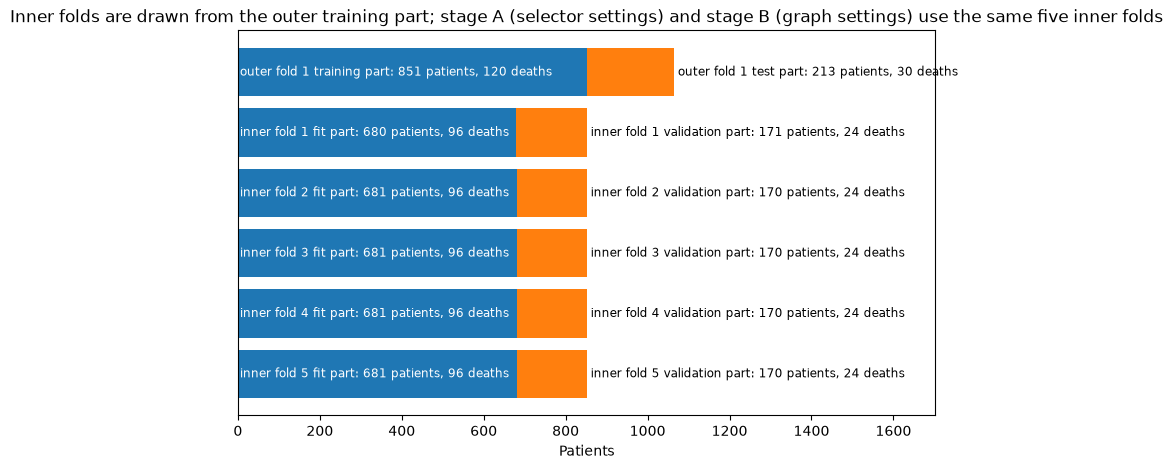

In [7]:
figure, axis = plt.subplots(figsize=(9, 5))
for position, (fit_name, score_name, part, (fit_rows, score_rows)) in enumerate(bars):
    fit_part, score_part = part.iloc[fit_rows], part.iloc[score_rows]
    axis.barh(-position, len(fit_part), color="tab:blue")
    axis.barh(-position, len(score_part), left=len(fit_part), color="tab:orange")
    axis.text(5, -position, part_label(fit_name, fit_part), va="center", color="white",
              fontsize=8.5)
    axis.text(len(part) + 10, -position, part_label(score_name, score_part), va="center",
              fontsize=8.5)
axis.set_xlim(0, len(table) * 1.6)  # room for the labels of the held-out parts
axis.set_yticks([])
axis.set_xlabel("Patients")
axis.set_title("Inner folds are drawn from the outer training part; stage A (selector settings) "
               "and stage B (graph settings) use the same five inner folds")
plt.show()

## Preprocessing inside the training part

The expression filter and the z-scoring of genes and age are fitted on the training part of each fold, inner or outer, and applied to its held-out part. The categorical covariates are one-hot encoded with their unknown level; the Cox models drop the most common level of each, learned on the training part. The unknown level marks patients followed longer in TCGA (notebook 1) and enters every model's clinical vector alike, so it moves the shared reference, not the paired differences.

In [8]:
def scaled_expression(train, other):
    """Keep genes expressed in enough training patients and z-score them on the training part."""
    expressed = (train[GENES] >= EXPRESSED_AT).mean() >= EXPRESSED_IN
    kept = list(expressed.index[expressed])
    scaler = StandardScaler().fit(train[kept])
    train_scaled = pd.DataFrame(scaler.transform(train[kept]), index=train.index, columns=kept)
    other_scaled = pd.DataFrame(scaler.transform(other[kept]), index=other.index, columns=kept)
    return train_scaled, other_scaled


def clinical_vectors(train, other, drop=None):
    """Age z-scored and stage, ER, PR and HER2 one-hot, fitted on the training part."""
    encoder = OneHotEncoder(drop=drop, sparse_output=False, handle_unknown="ignore")
    encoder.fit(train[CATEGORIES])
    scaler = StandardScaler().fit(train[["age"]])
    vectors = []
    for part in (train, other):
        age = scaler.transform(part[["age"]])
        vectors.append(np.hstack([age, encoder.transform(part[CATEGORIES])]))
    return vectors


def reference_levels(train):
    """The most common level of each category in a training part, dropped by the Cox models."""
    return [train[name].mode()[0] for name in CATEGORIES]

## Scores

Harrell's C is the share of patient pairs whose predicted risks are in the same order as their survival times, among the pairs the data can order; 0.5 is chance. It is the primary score, and every paired interval below uses it. Uno's C reweights the pairs for censoring and is read up to five years; with TCGA's short follow-up the pairs near five years carry large weights, so it is the secondary and noisier score.

In [9]:
def harrell(part, risk):
    """Harrell's C-index of a risk score on one part."""
    return concordance_index_censored(part["os_event"].astype(bool), part["os_days"], risk)[0]


def uno(train, part, risk):
    """Uno's C-index up to the horizon, with censoring weights from the training part."""
    return concordance_index_ipcw(outcome_of(train), outcome_of(part), risk, tau=HORIZON_DAYS)[0]


def both_scores(train, test, risk):
    """Harrell's C and Uno's C of one risk score on a test part."""
    scores = {"Harrell's C": float(harrell(test, risk)),
              "Uno's C (5 years)": float(uno(train, test, risk))}
    return scores

## Stage A: the selector's settings

The selector is an elastic-net Cox model: a Cox model whose penalty sets most gene coefficients to zero, so the genes left are the selected list. Each inner fit part computes its own path of 25 penalties per L1 ratio, from the penalty that keeps no gene down to 5% of it; its validation part only scores them. A candidate is an L1 ratio and a place on the path, eligible when every inner fit part keeps 10 to 1,000 genes there; the highest mean score wins, ties going to the stronger penalty.

In [10]:
def selector_inputs(train, other, with_clinical):
    """Selector features of a training and a held-out part, and the names of the gene columns."""
    x_train, x_other = scaled_expression(train, other)
    train_features = x_train.to_numpy()
    other_features = x_other.to_numpy()
    if with_clinical:
        c_train, c_other = clinical_vectors(train, other, reference_levels(train))
        train_features = np.hstack([train_features, c_train])
        other_features = np.hstack([other_features, c_other])
    return train_features, other_features, list(x_train.columns)


def selector_path(features, outcome, l1_ratio, gene_count):
    """The library's path on one training part, its penalties set by the gene columns alone."""
    genes_only = CoxnetSurvivalAnalysis(l1_ratio=l1_ratio, n_alphas=PENALTIES,
                                        alpha_min_ratio=SMALLEST_PENALTY)
    genes_only.fit(features[:, :gene_count], outcome)
    assert len(genes_only.alphas_) == PENALTIES, "the library returned a shorter path"
    if features.shape[1] == gene_count:
        return genes_only
    factor = np.ones(features.shape[1])
    factor[gene_count:] = CLINICAL_SHARE  # the clinical columns after the genes
    model = CoxnetSurvivalAnalysis(l1_ratio=l1_ratio, alphas=genes_only.alphas_,
                                   penalty_factor=factor)
    model.fit(features, outcome)
    assert len(model.alphas_) == PENALTIES, "the refit with clinical columns shortened the path"
    return model

In [11]:
def inner_candidates(fit_part, score_part, l1_ratio, with_clinical):
    """One inner fold: its own path, the genes kept at each place and the validation C-index."""
    fit_features, score_features, genes = selector_inputs(fit_part, score_part, with_clinical)
    model = selector_path(fit_features, outcome_of(fit_part), l1_ratio, len(genes))
    counts = (model.coef_[:len(genes)] != 0).sum(axis=0)
    rows = []
    for place, penalty in enumerate(model.alphas_, start=1):
        risk = model.predict(score_features, alpha=penalty)
        row = {"place": place, "penalty": float(penalty), "genes": int(counts[place - 1]),
               "inner C": float(harrell(score_part, risk))}
        rows.append(row)
    return rows

In [12]:
def stage_a(train, inner, with_clinical=False):
    """Choose the L1 ratio and the place on the path by the mean inner validation C-index."""
    rows = []
    for l1_ratio in L1_RATIOS:
        for fold, (fit_rows, score_rows) in enumerate(inner, start=1):
            fit_part, score_part = train.iloc[fit_rows], train.iloc[score_rows]
            for row in inner_candidates(fit_part, score_part, l1_ratio, with_clinical):
                row["l1 ratio"] = l1_ratio
                row["inner fold"] = fold
                rows.append(row)
    per_fold = pd.DataFrame(rows)
    grid = per_fold.groupby(["l1 ratio", "place"], as_index=False).agg(
        mean_c=("inner C", "mean"), fewest=("genes", "min"), most=("genes", "max"))
    grid.columns = ["l1 ratio", "place", "inner mean C", "fewest genes", "most genes"]
    grid["eligible"] = (grid["fewest genes"] >= LIST_MIN) & (grid["most genes"] <= LIST_MAX)
    assert grid["eligible"].any(), "no setting keeps 10 to 1,000 genes in every inner fit part"
    ranked = grid[grid["eligible"]].sort_values(["inner mean C", "place"], ascending=[False, True])
    return ranked.iloc[0], grid, per_fold


def select_genes(train, other, setting, with_clinical=False):
    """Refit the selector on a training part's own path; its genes and risk at the chosen place."""
    train_features, other_features, genes = selector_inputs(train, other, with_clinical)
    model = selector_path(train_features, outcome_of(train), setting["l1 ratio"], len(genes))
    index = int(setting["place"]) - 1  # places count from 1, the strongest penalty
    nonzero = model.coef_[:len(genes), index] != 0
    risk = model.predict(other_features, alpha=model.alphas_[index])
    return list(pd.Index(genes)[nonzero]), risk, float(model.alphas_[index])

## The graph model

Each patient is one graph: the selected genes are its nodes, the patient's z-scored expression of a gene is the node's feature, and STRING edges connect the nodes. Two message-passing layers pass information between neighbours, mean pooling makes one vector per patient, the clinical vector is appended and a two-layer head gives one log-hazard. The registered layer is GraphSAGE; GCN, GATv2 and GIN are compared with it, and GCN and GATv2 also read an edge's STRING score. A gene without an edge keeps only its own feature in every layer type.

In [13]:
def graph_layer(kind, in_size, out_size):
    """One message-passing layer of the named kind."""
    if kind == "GCN":
        return GCNConv(in_size, out_size)
    if kind == "GATv2":
        return GATv2Conv(in_size, out_size, heads=ATTENTION_HEADS, edge_dim=1)
    if kind == "GIN":
        inner = torch.nn.Sequential(torch.nn.Linear(in_size, out_size), torch.nn.ReLU(),
                                    torch.nn.Linear(out_size, out_size))
        return GINConv(inner)
    assert kind == "GraphSAGE", f"unknown layer type {kind}"
    return SAGEConv(in_size, out_size)


def apply_layer(layer, features, graphs):
    """One layer on the patient graphs; GCN reads the STRING score as weight, GATv2 as feature."""
    if isinstance(layer, GCNConv):
        return layer(features, graphs.edge_index, graphs.edge_weight)
    if isinstance(layer, GATv2Conv):
        return layer(features, graphs.edge_index, graphs.edge_weight.unsqueeze(1))
    return layer(features, graphs.edge_index)

In [14]:
class GraphModel(torch.nn.Module):
    """Two message-passing layers, mean pooling, the clinical vector and a two-layer head."""

    def __init__(self, hidden, dropout, clinical_size, gene_count=0, identity_size=0,
                 layer="GraphSAGE"):
        """Layers sized by the width, the dropout, the clinical vector and the optional identity."""
        super().__init__()
        self.identity = None
        if identity_size:
            self.identity = torch.nn.Embedding(gene_count, identity_size)
        self.layer_1 = graph_layer(layer, 1 + identity_size, hidden)
        self.layer_2 = graph_layer(layer, hidden, hidden)
        self.dropout = torch.nn.Dropout(dropout)
        self.head = torch.nn.Sequential(torch.nn.Linear(hidden + clinical_size, hidden),
                                        torch.nn.ReLU(), torch.nn.Dropout(dropout),
                                        torch.nn.Linear(hidden, 1))

    def forward(self, graphs, clinical):
        """One log-hazard per patient graph."""
        features = graphs.x
        if self.identity is not None:
            count = self.identity.num_embeddings
            gene_position = torch.arange(len(features), device=features.device) % count
            features = torch.cat([features, self.identity(gene_position)], dim=1)
        hidden = self.dropout(torch.relu(apply_layer(self.layer_1, features, graphs)))
        hidden = self.dropout(torch.relu(apply_layer(self.layer_2, hidden, graphs)))
        pooled = global_mean_pool(hidden, graphs.batch)
        return self.head(torch.cat([pooled, clinical], dim=1)).squeeze(1)

## The plain networks

Three comparison rows use a multilayer perceptron (MLP), a network of fully connected layers that reads the selected genes as one vector, so each input position is one known gene. Its gene part has two layers of the graph model's width and dropout, and the same head takes their output and the clinical vector. Without genes the head reads the clinical vector alone; without clinical columns, the gene part alone.

In [15]:
class PlainModel(torch.nn.Module):
    """Two fully connected layers on the genes, then a two-layer head with the clinical vector."""

    def __init__(self, hidden, dropout, gene_count, clinical_size):
        """Layers sized by the width, the dropout, the number of genes and the clinical vector."""
        super().__init__()
        self.genes = None
        head_size = clinical_size
        if gene_count:
            self.genes = torch.nn.Sequential(torch.nn.Linear(gene_count, hidden), torch.nn.ReLU(),
                                             torch.nn.Dropout(dropout),
                                             torch.nn.Linear(hidden, hidden), torch.nn.ReLU(),
                                             torch.nn.Dropout(dropout))
            head_size = head_size + hidden
        self.head = torch.nn.Sequential(torch.nn.Linear(head_size, hidden), torch.nn.ReLU(),
                                        torch.nn.Dropout(dropout), torch.nn.Linear(hidden, 1))

    def forward(self, genes, clinical):
        """One log-hazard per patient."""
        if self.genes is None:
            return self.head(clinical).squeeze(1)
        return self.head(torch.cat([self.genes(genes), clinical], dim=1)).squeeze(1)

## Inputs, training and prediction

A network's inputs are the patient graphs or the gene matrix, then the clinical vectors, on the device of the settings. Every network starts from the same seed and is trained the same way: Adam, the Cox partial likelihood on all training patients at once, a fixed number of updates. On a GPU the patients pass in chunks to fit in memory: all log-hazards first, the loss once, then each chunk sends back its share of the gradient, which is the same full-batch gradient.

In [16]:
def edges_among(genes, edge_list):
    """The rows of an edge list whose two genes are both in the given list."""
    return edge_list[edge_list["gene_a"].isin(genes) & edge_list["gene_b"].isin(genes)]


def patient_graphs(expression, genes, edge_table):
    """One graph per patient on the given genes, with the edges between them and their score."""
    position = pd.Series(range(len(genes)), index=genes)
    kept = edges_among(genes, edge_table)
    ends = np.vstack([position[kept["gene_a"]].to_numpy(), position[kept["gene_b"]].to_numpy()])
    edge_index = torch.tensor(np.hstack([ends, ends[::-1]]), dtype=torch.long)
    score = torch.tensor(kept["score"].to_numpy() / 1000, dtype=torch.float32)  # STRING's 0 to 1
    weight = torch.cat([score, score])  # the same score in both directions
    values = torch.tensor(expression[genes].to_numpy(), dtype=torch.float32)
    graphs = []
    for row in values:
        graphs.append(Data(x=row.unsqueeze(1), edge_index=edge_index, edge_weight=weight))
    size = PATIENTS_PER_CHUNK or len(graphs)
    batches = []
    for start in range(0, len(graphs), size):
        batches.append(Batch.from_data_list(graphs[start:start + size]).to(DEVICE))
    return batches


def model_inputs(variant, expression, genes, clinical):
    """A network's inputs in chunks of patients: graphs or a gene matrix, with clinical vectors."""
    clinical = torch.tensor(clinical, dtype=torch.float32, device=DEVICE)
    if variant["kind"] == "graph":
        chunks = []
        start = 0
        for batch in patient_graphs(expression, genes, variant["edges"]):
            chunks.append((batch, clinical[start:start + batch.num_graphs]))
            start += batch.num_graphs
        return chunks
    gene_matrix = torch.tensor(expression[genes].to_numpy(), dtype=torch.float32, device=DEVICE)
    if not variant["clinical"]:
        clinical = clinical[:, :0]  # no clinical column
    return [(gene_matrix, clinical)]

In [17]:
def new_model(variant, inputs, hidden, dropout):
    """An untrained network of the variant's kind, its weights started from the fixed seed."""
    torch.manual_seed(TORCH_SEED)
    first, clinical = inputs[0]
    if variant["kind"] == "graph":
        gene_count = first.x.shape[0] // first.num_graphs  # every patient graph has the same nodes
        model = GraphModel(hidden, dropout, clinical.shape[1], gene_count, variant["identity"],
                           variant.get("layer", "GraphSAGE"))
        return model.to(DEVICE)
    return PlainModel(hidden, dropout, first.shape[1], clinical.shape[1]).to(DEVICE)


def outcome_tensors(part):
    """The event flags and times of one part, on the device."""
    event = torch.tensor(part["os_event"].to_numpy(), dtype=torch.bool, device=DEVICE)
    days = torch.tensor(part["os_days"].to_numpy(), dtype=torch.float32, device=DEVICE)
    return event, days

In [18]:
def all_patients(model, inputs):
    """The log-hazards of every patient, chunk after chunk."""
    return torch.cat([model(*chunk) for chunk in inputs])


def backward_in_chunks(model, inputs, event, days):
    """The full-batch gradient taken chunk by chunk: the loss once, then each chunk's share."""
    state = torch.cuda.get_rng_state()
    with torch.no_grad():
        risks = all_patients(model, inputs)
    risks.requires_grad_(True)
    loss = neg_partial_log_likelihood(risks, event, days, ties_method="breslow")
    loss.backward()
    torch.cuda.set_rng_state(state)  # the second pass draws the same dropout masks
    start = 0
    for chunk in inputs:
        chunk_risk = model(*chunk)
        chunk_risk.backward(risks.grad[start:start + len(chunk_risk)])
        start += len(chunk_risk)
    return loss

In [19]:
def update(model, optimiser, inputs, event, days):
    """One full-batch Adam update with the Breslow Cox loss; returns the loss it started from."""
    optimiser.zero_grad()
    if len(inputs) == 1:  # one pass, as in the registered run
        loss = neg_partial_log_likelihood(model(*inputs[0]), event, days, ties_method="breslow")
        loss.backward()
    else:
        loss = backward_in_chunks(model, inputs, event, days)
    optimiser.step()
    return float(loss)


def train_network(model, inputs, part, learning_rate=LEARNING_RATE):
    """Train a network for the fixed number of updates with the Breslow Cox loss, full batch."""
    optimiser = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=WEIGHT_DECAY)
    event, days = outcome_tensors(part)
    model.train()
    for epoch in range(EPOCHS):
        update(model, optimiser, inputs, event, days)
    return model


def log_hazard(model, inputs):
    """The trained network's log-hazard per patient, with dropout off."""
    model.eval()
    with torch.no_grad():
        return all_patients(model, inputs).cpu().numpy()

## Stage B: the graph model's settings

On the same five inner folds, the selector is refitted at the chosen setting on the inner fit part alone, its genes form the graph, one model per width and dropout (and learning rate, where a row chooses it) is trained on the fit part and scored on the validation part, and the highest mean score wins. The same functions tune the comparison rows. An inner fit part with fewer than two genes would score 0.5; stage A's eligibility rule prevents it, and the count stays as a check.

In [20]:
def network_grid(variant):
    """The width, dropout and learning-rate settings stage B tries for one network."""
    grid = []
    for hidden in HIDDEN_SIZES:
        for dropout in DROPOUTS:
            for rate in variant.get("learning rates", [LEARNING_RATE]):
                grid.append((hidden, dropout, rate))
    return grid


def inner_network_scores(fit_part, score_part, setting, variant):
    """Validation C-index of each network setting on one inner fold, genes selected inside it."""
    genes = []
    if variant["genes"]:
        genes, _, _ = select_genes(fit_part, score_part, setting)
    scores = {}
    if variant["genes"] and len(genes) < 2:
        for network_setting in network_grid(variant):
            scores[network_setting] = 0.5
        return scores, len(genes)
    x_fit, x_score = scaled_expression(fit_part, score_part)
    c_fit, c_score = clinical_vectors(fit_part, score_part)
    fit_inputs = model_inputs(variant, x_fit, genes, c_fit)
    score_inputs = model_inputs(variant, x_score, genes, c_score)
    for hidden, dropout, rate in network_grid(variant):
        untrained = new_model(variant, fit_inputs, hidden, dropout)
        model = train_network(untrained, fit_inputs, fit_part, rate)
        scores[(hidden, dropout, rate)] = harrell(score_part, log_hazard(model, score_inputs))
    return scores, len(genes)

In [21]:
def stage_b(train, inner, setting, variant):
    """Choose the network setting by the mean inner validation C-index."""
    totals = {}
    few_genes = 0
    for fit_rows, score_rows in inner:
        scores, gene_count = inner_network_scores(train.iloc[fit_rows], train.iloc[score_rows],
                                                  setting, variant)
        few_genes += int(variant["genes"] and gene_count < 2)
        for network_setting, score in scores.items():
            totals[network_setting] = totals.get(network_setting, 0) + score / len(inner)
    rows = []
    for (hidden, dropout, rate), score in totals.items():
        row = {"hidden size": hidden, "dropout": dropout, "learning rate": rate,
               "inner mean C": float(score)}
        rows.append(row)
    inner_table = pd.DataFrame(rows).sort_values("inner mean C", ascending=False)
    return inner_table.iloc[0], inner_table, few_genes

## Stage C: one model per outer fold, scored once

With both settings chosen, the selector is refitted on the whole outer training part at the chosen place on that part's own path and gives this fold's gene list; the graph model is trained on that part with the chosen setting, and the outer test part is scored once. The clinical-only Cox and the refitted selector's own risk are scored on the same split as reference rows.

In [22]:
def clinical_cox(train, test):
    """The library's Cox model on the five covariates, the most common level of each dropped."""
    c_train, c_test = clinical_vectors(train, test, reference_levels(train))
    model = CoxPHSurvivalAnalysis(alpha=CLINICAL_RIDGE).fit(c_train, outcome_of(train))
    return model.predict(c_test)


def network_scores(train, test, genes, network_setting, variant):
    """Train one network on the training part at a chosen setting; score the test part."""
    x_train, x_test = scaled_expression(train, test)
    c_train, c_test = clinical_vectors(train, test)
    train_inputs = model_inputs(variant, x_train, genes, c_train)
    test_inputs = model_inputs(variant, x_test, genes, c_test)
    hidden = int(network_setting["hidden size"])
    dropout = float(network_setting["dropout"])
    rate = float(network_setting.get("learning rate", LEARNING_RATE))
    untrained = new_model(variant, train_inputs, hidden, dropout)
    model = train_network(untrained, train_inputs, train, rate)
    if variant.get("identity"):
        assert model.identity.num_embeddings == len(genes), "one identity row per gene of the list"
    return both_scores(train, test, log_hazard(model, test_inputs))


def stage_c(train, test, setting, graph_setting):
    """Fit the selector, the graph model and the reference rows; score the test part once."""
    genes, selector_risk, penalty = select_genes(train, test, setting)
    scores = {"graph model": network_scores(train, test, genes, graph_setting, BASE),
              "selector as a model": both_scores(train, test, selector_risk),
              "clinical-only Cox": both_scores(train, test, clinical_cox(train, test))}
    return genes, penalty, scores

## Running the outer folds

Each outer fold runs stages A, B and C and writes its own file, so a run that stops loses one fold and a fold whose file exists is skipped. The gene list of each fold is saved beside it. The functions after the registered ones serve the comparison rows, and the last cell of this part runs whatever has no saved file. The first run in `first_run/` used the same fold seed, so it scored these same test parts before the code review changed stage A.

In [23]:
def stage_a_record(setting, grid, per_fold):
    """Stage A's choice with its grid and every inner fold's own path, as plain values."""
    record = {"l1 ratio": float(setting["l1 ratio"]), "place": int(setting["place"]),
              "inner mean C": float(setting["inner mean C"]),
              "fewest genes": int(setting["fewest genes"]),
              "most genes": int(setting["most genes"]),
              "eligible settings": int(grid["eligible"].sum()),
              "settings": grid.to_dict("records"), "inner folds": per_fold.to_dict("records")}
    return record


def stage_b_record(network_setting, inner_table, few_genes):
    """Stage B's choice with its grid, as plain values."""
    record = {"hidden size": int(network_setting["hidden size"]),
              "dropout": float(network_setting["dropout"]),
              "learning rate": float(network_setting["learning rate"]),
              "inner mean C": float(network_setting["inner mean C"]),
              "inner folds with fewer than 2 genes": few_genes,
              "settings": inner_table.to_dict("records")}
    return record

In [24]:
BASE = {"kind": "graph", "genes": True, "edges": edges, "identity": 0}  # the registered model
NO_EDGES = {"kind": "graph", "genes": True, "edges": edges.iloc[:0], "identity": 0}  # no edge


def run_outer_fold(number, train_rows, test_rows):
    """Stages A, B and C of one outer fold, written to the fold's own file."""
    train, test = table.iloc[train_rows], table.iloc[test_rows]
    assert set(train.index).isdisjoint(test.index), "a patient is in both parts"
    inner = folds(train, INNER_FOLDS)
    started = time.time()
    setting, grid, per_fold = stage_a(train, inner)
    after_a = time.time()
    graph_setting, inner_table, few_genes = stage_b(train, inner, setting, BASE)
    after_b = time.time()
    genes, penalty, scores = stage_c(train, test, setting, graph_setting)
    between = edges_among(genes, edges)
    patients = {"training": len(train), "test": len(test),
                "training deaths": int(train["os_event"].sum()),
                "test deaths": int(test["os_event"].sum())}
    stage_c_record = {"genes": len(genes), "penalty": penalty, "edges": len(between),
                      "genes with an edge": len(set(between["gene_a"]) | set(between["gene_b"])),
                      "scores": scores}
    minutes = {"stage A": round((after_a - started) / 60, 1),
               "stage B": round((after_b - after_a) / 60, 1),
               "stage C": round((time.time() - after_b) / 60, 1)}
    record = {"fold": number, "patients": patients,
              "stage A": stage_a_record(setting, grid, per_fold),
              "stage B": stage_b_record(graph_setting, inner_table, few_genes),
              "stage C": stage_c_record, "minutes": minutes}
    (RESULTS / f"outer_fold_{number}.json").write_text(json.dumps(record, indent=1))
    (RESULTS / f"outer_fold_{number}_genes.txt").write_text("\n".join(genes) + "\n")

In [25]:
def add_no_graph_row(number, train_rows, test_rows):
    """The same model with the edges removed, on the same split, list and setting."""
    record = json.loads((RESULTS / f"outer_fold_{number}.json").read_text())
    if "no-graph model" in record["stage C"]["scores"]:
        return
    train, test = table.iloc[train_rows], table.iloc[test_rows]
    genes, _, _ = select_genes(train, test, record["stage A"])
    assert len(genes) == record["stage C"]["genes"], "the refit selects another list"
    scores = network_scores(train, test, genes, record["stage B"], NO_EDGES)
    record["stage C"]["scores"]["no-graph model"] = scores
    (RESULTS / f"outer_fold_{number}.json").write_text(json.dumps(record, indent=1))

In [26]:
IDENTITY_700 = "graph model, STRING 700, gene identity"
COMPARISON_ROWS = {
    "selector plus clinical covariates": {"kind": "cox"},
    "clinical MLP": {"kind": "plain", "genes": False, "clinical": True},
    "gene MLP": {"kind": "plain", "genes": True, "clinical": False},
    "gene plus clinical MLP": {"kind": "plain", "genes": True, "clinical": True},
    IDENTITY_700: {"kind": "graph", "genes": True, "edges": edges, "identity": IDENTITY_SIZE},
    "no-graph model, gene identity": {"kind": "graph", "genes": True, "edges": edges.iloc[:0],
                                      "identity": IDENTITY_SIZE, "settings from": IDENTITY_700},
    "graph model, STRING 400": {"kind": "graph", "genes": True, "edges": denser_edges,
                                "identity": 0},
    "graph model, STRING 400, gene identity": {"kind": "graph", "genes": True,
                                               "edges": denser_edges, "identity": IDENTITY_SIZE}}
ROW_DIR = RESULTS / "comparison_rows"


def row_file(name, number):
    """The fold file of one comparison row."""
    folder = ROW_DIR / name.replace(", ", "_").replace(" ", "_").lower()
    folder.mkdir(parents=True, exist_ok=True)
    return folder / f"outer_fold_{number}.json"


def recorded_setting(number):
    """The selector setting of one saved fold, without its scores, and the fold's record."""
    record = json.loads((RESULTS / f"outer_fold_{number}.json").read_text())
    record.pop("stage C")  # the recorded scores are never read by a comparison row
    return record["stage A"], record

The rows added after the code review compare layer types: GraphSAGE, GCN, GATv2 and GIN at STRING 700 and 400, each tuning its own width and dropout on the same inner folds, and each with a control that keeps its genes, settings and seed and removes the edges. The learning-rate rows (GraphSAGE at both cut-offs, GCN and GIN at 400) choose the learning rate as well; they run only if the training-curve rule asks for them.

In [27]:
LAYER_ROWS = {}
for layer in GRAPH_LAYERS:
    for label, edge_list in [("STRING 700", edges), ("STRING 400", denser_edges)]:
        name = f"{layer}, {label}"
        LAYER_ROWS[name] = {"kind": "graph", "genes": True, "edges": edge_list, "identity": 0,
                            "layer": layer}
        LAYER_ROWS[f"{name}, edges removed"] = {"kind": "graph", "genes": True,
                                                "edges": edge_list.iloc[:0], "identity": 0,
                                                "layer": layer, "settings from": name}
RATE_ROWS = {}
for layer, label, edge_list in [("GraphSAGE", "STRING 700", edges),
                                ("GraphSAGE", "STRING 400", denser_edges),
                                ("GCN", "STRING 400", denser_edges),
                                ("GIN", "STRING 400", denser_edges)]:  # GATv2 is ten times slower
    name = f"{layer}, {label}, learning rate chosen"
    RATE_ROWS[name] = {"kind": "graph", "genes": True, "edges": edge_list, "identity": 0,
                       "layer": layer, "learning rates": LEARNING_RATES}
    RATE_ROWS[f"{name}, edges removed"] = {"kind": "graph", "genes": True,
                                           "edges": edge_list.iloc[:0], "identity": 0,
                                           "layer": layer, "settings from": name}

In [28]:
def selector_plus_clinical(train, test, inner):
    """Elastic-net Cox on the genes plus the clinical columns, with its own stage A."""
    setting, grid, per_fold = stage_a(train, inner, with_clinical=True)
    genes, risk, penalty = select_genes(train, test, setting, with_clinical=True)
    out = {"stage A": stage_a_record(setting, grid, per_fold), "genes": len(genes),
           "penalty": penalty, "edges": 0, "scores": both_scores(train, test, risk)}
    return out


def tuned_network(train, test, setting, variant):
    """Stage B for one network on the same inner folds, then one score on the test part."""
    network_setting, inner_table, few_genes = stage_b(train, folds(train, INNER_FOLDS), setting,
                                                      variant)
    genes = []
    if variant["genes"]:
        genes, _, _ = select_genes(train, test, setting)
    edge_list = variant.get("edges", edges.iloc[:0])
    out = {"stage B": stage_b_record(network_setting, inner_table, few_genes),
           "genes": len(genes), "edges": len(edges_among(genes, edge_list)),
           "scores": network_scores(train, test, genes, network_setting, variant)}
    return out


def network_without_tuning(variant, number, train, test, setting):
    """The control: the genes, width, dropout and seed of another row, without its edges."""
    source = json.loads(row_file(variant["settings from"], number).read_text())
    genes, _, _ = select_genes(train, test, setting)
    assert len(genes) == source["genes"], "the refit selects another list than the source row"
    out = {"settings from": variant["settings from"], "stage B": source["stage B"],
           "genes": len(genes), "edges": 0,
           "scores": network_scores(train, test, genes, source["stage B"], variant)}
    return out

In [29]:
def run_comparison_fold(name, variant, number, train_rows, test_rows):
    """One comparison row on one outer fold, from the fold's recorded split and selector setting."""
    setting, record = recorded_setting(number)
    train, test = table.iloc[train_rows], table.iloc[test_rows]
    assert len(train) == record["patients"]["training"], "the split differs from the saved fold"
    assert set(train.index).isdisjoint(test.index), "a patient is in both parts"
    started = time.time()
    if variant["kind"] == "cox":
        out = selector_plus_clinical(train, test, folds(train, INNER_FOLDS))
    elif "settings from" in variant:
        out = network_without_tuning(variant, number, train, test, setting)
    else:
        out = tuned_network(train, test, setting, variant)
    out["fold"] = number
    out["row"] = name
    out["minutes"] = round((time.time() - started) / 60, 1)
    if "layer" in variant:
        out["device"] = DEVICE_NAME  # the rows added after the review record their device
    row_file(name, number).write_text(json.dumps(out, indent=1))


def compute_row(name, variant):
    """Every outer fold of one comparison row that has no saved file yet."""
    for number, (train_rows, test_rows) in enumerate(outer, start=1):
        if not row_file(name, number).exists():
            run_comparison_fold(name, variant, number, train_rows, test_rows)

In [30]:
RESULTS.mkdir(exist_ok=True)
if COMPUTE:
    for number, (train_rows, test_rows) in enumerate(outer, start=1):
        if not (RESULTS / f"outer_fold_{number}.json").exists():
            run_outer_fold(number, train_rows, test_rows)
    if RUN_NO_GRAPH:
        for number, (train_rows, test_rows) in enumerate(outer, start=1):
            add_no_graph_row(number, train_rows, test_rows)
    if RUN_COMPARISON_ROWS:
        for rows_of_one_kind in [COMPARISON_ROWS, LAYER_ROWS]:
            for name, variant in rows_of_one_kind.items():
                compute_row(name, variant)
fold_files = sorted(RESULTS.glob("outer_fold_*.json"))
fold_records = [json.loads(path.read_text()) for path in fold_files]
display(Markdown(f"{len(fold_records)} of {OUTER_FOLDS} outer folds have a saved file."))

5 of 5 outer folds have a saved file.

## Training length: the curve over 400 updates

This check trains the registered graph model of each outer fold, at that fold's chosen settings, for 400 updates at the registered learning rate and at ten times it, on the inner folds of the outer training part only, and records the training loss and the inner validation C-index every 10 updates. A rule set before the run decides whether the learning-rate rows are computed: a mean validation gain of at least 0.005 over the registered 40 updates.

In [31]:
CURVE_DIR = RESULTS / "training_curve"


def curve_inputs(fit_part, score_part, setting):
    """The registered graph model's inputs on one inner fold, genes selected on the fit part."""
    genes, _, _ = select_genes(fit_part, score_part, setting)
    x_fit, x_score = scaled_expression(fit_part, score_part)
    c_fit, c_score = clinical_vectors(fit_part, score_part)
    return model_inputs(BASE, x_fit, genes, c_fit), model_inputs(BASE, x_score, genes, c_score)


def curve_points(parts, inputs, network_setting, rate):
    """Training loss and validation C-index every few updates of one model on one inner fold."""
    fit_part, score_part = parts
    fit_inputs, score_inputs = inputs
    hidden, dropout = int(network_setting["hidden size"]), float(network_setting["dropout"])
    model = new_model(BASE, fit_inputs, hidden, dropout)
    optimiser = torch.optim.Adam(model.parameters(), lr=rate, weight_decay=WEIGHT_DECAY)
    event, days = outcome_tensors(fit_part)
    points = []
    for step in range(1, CURVE_STEPS + 1):
        model.train()
        loss = update(model, optimiser, fit_inputs, event, days)
        if step % CURVE_EVERY == 0:
            validation = harrell(score_part, log_hazard(model, score_inputs))
            point = {"update": step, "training loss": loss, "validation C": float(validation)}
            points.append(point)
    return points

In [32]:
def training_curve(number, train_rows):
    """The curves of one outer fold's inner folds at its registered settings, saved to a file."""
    record = json.loads((RESULTS / f"outer_fold_{number}.json").read_text())
    train = table.iloc[train_rows]
    assert len(train) == record["patients"]["training"], "the split differs from the saved fold"
    points = []
    for fold, (fit_rows, score_rows) in enumerate(folds(train, INNER_FOLDS), start=1):
        parts = (train.iloc[fit_rows], train.iloc[score_rows])
        inputs = curve_inputs(*parts, record["stage A"])
        for rate in CURVE_RATES:
            for point in curve_points(parts, inputs, record["stage B"], rate):
                point["outer fold"] = number
                point["inner fold"] = fold
                point["learning rate"] = rate
                points.append(point)
    out = {"fold": number, "device": DEVICE_NAME, "points": points}
    CURVE_DIR.mkdir(exist_ok=True)
    (CURVE_DIR / f"outer_fold_{number}.json").write_text(json.dumps(out, indent=1))


if COMPUTE:
    for number, (train_rows, test_rows) in enumerate(outer, start=1):
        if not (CURVE_DIR / f"outer_fold_{number}.json").exists():
            training_curve(number, train_rows)
curve_frames = []
for path in sorted(CURVE_DIR.glob("outer_fold_*.json")) if CURVE_DIR.exists() else []:
    curve_frames.append(pd.DataFrame(json.loads(path.read_text())["points"]))

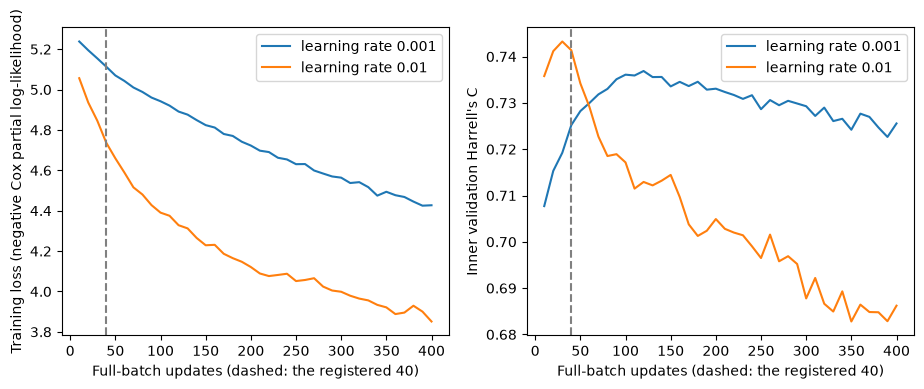

In [33]:
rate_rows_wanted = False
if curve_frames:
    points = pd.concat(curve_frames)
    measures = ["training loss", "validation C"]
    mean_curve = points.groupby(["learning rate", "update"])[measures].mean()
    reference = mean_curve.loc[(LEARNING_RATE, EPOCHS), "validation C"]
    best_rate, best_update = mean_curve["validation C"].idxmax()
    gain = mean_curve.loc[(best_rate, best_update), "validation C"] - reference
    rate_rows_wanted = bool(gain >= CURVE_GAIN)
    figure, axes = plt.subplots(1, 2, figsize=(11, 4))
    for rate, curve in mean_curve.groupby(level="learning rate"):
        steps = curve.index.get_level_values("update")
        axes[0].plot(steps, curve["training loss"], label=f"learning rate {rate}")
        axes[1].plot(steps, curve["validation C"], label=f"learning rate {rate}")
    axes[0].set_ylabel("Training loss (negative Cox partial log-likelihood)")
    axes[1].set_ylabel("Inner validation Harrell's C")
    for axis in axes:
        axis.axvline(EPOCHS, color="grey", linestyle="--")
        axis.set_xlabel("Full-batch updates (dashed: the registered 40)")
        axis.legend()
    plt.show()

In [34]:
if curve_frames:
    curves = len(points[["outer fold", "inner fold"]].drop_duplicates())
    verdict = {True: "is met, so the learning-rate rows are computed",
               False: "is not met, so the learning-rate rows are not computed"}
    display(Markdown(f"Mean over {curves} inner folds: at learning rate {LEARNING_RATE} the "
                     f"validation C-index is {reference:.3f} after {EPOCHS} updates; the highest "
                     f"mean is {reference + gain:.3f}, at learning rate {best_rate} after "
                     f"{best_update} updates. The rule set before the run, a gain of at least "
                     f"{CURVE_GAIN}, {verdict[rate_rows_wanted]}."))
else:
    display(Markdown("The training curves are not yet computed."))

Mean over 25 inner folds: at learning rate 0.001 the validation C-index is 0.725 after 40 updates; the highest mean is 0.743, at learning rate 0.01 after 30 updates. The rule set before the run, a gain of at least 0.005, is met, so the learning-rate rows are computed.

## Stage A results

Per outer fold: the chosen L1 ratio and place on the path (1 is the strongest of the 25 penalties), the mean inner validation C-index at that setting, the fewest and most genes it kept in the five inner fit parts, the penalty at that place on the outer training part's own path, the genes it keeps there and the STRING edges among them.

In [35]:
rows = []
for record in fold_records:
    chosen = record["stage A"]
    row = {"outer fold": record["fold"], "L1 ratio": chosen["l1 ratio"],
           "place on the path": chosen["place"], "inner mean C": round(chosen["inner mean C"], 3),
           "eligible settings of 75": chosen["eligible settings"],
           "genes in the inner fit parts": f"{chosen['fewest genes']} to {chosen['most genes']}",
           "penalty": round(record["stage C"]["penalty"], 4),
           "genes selected": record["stage C"]["genes"], "edges": record["stage C"]["edges"],
           "genes with an edge": record["stage C"]["genes with an edge"]}
    rows.append(row)
stage_a_table = pd.DataFrame(rows).set_index("outer fold")
stage_a_table.to_csv(RESULTS / "stage_a.csv")
display(Markdown(f"Stage A, {len(fold_records)} of {OUTER_FOLDS} folds."))
stage_a_table

Stage A, 5 of 5 folds.

,L1 ratio,place on the path,inner mean C,eligible settings of 75,genes in the inner fit parts,penalty,genes selected,edges,genes with an edge
outer fold,,,,,,,,,
1,0.5,16,0.684,63,261 to 318,0.0194,300,63,75
2,0.5,13,0.691,60,158 to 195,0.0291,198,24,36
3,0.5,25,0.656,63,399 to 440,0.0064,472,153,168
4,0.5,24,0.689,66,406 to 432,0.0053,481,144,145
5,0.5,25,0.687,63,376 to 442,0.0066,476,142,143


In [36]:
ratios = sorted(stage_a_table["L1 ratio"].unique())
offered = ", ".join(str(ratio) for ratio in L1_RATIOS)
chosen = ", ".join(str(ratio) for ratio in ratios)
ratio_text = f"the folds chose L1 ratios of {chosen} ({offered} offered)"
if ratios == [min(L1_RATIOS)]:
    ratio_text = (f"every fold chose an L1 ratio of {ratios[0]}, the lowest value the grid offers "
                  f"({offered}), so the selector sat at the edge of its grid")
isolated = 1 - stage_a_table["genes with an edge"] / stage_a_table["genes selected"]
display(Markdown(f"The chosen lists hold {stage_a_table['genes selected'].min()} to "
                 f"{stage_a_table['genes selected'].max()} genes; {ratio_text}. "
                 f"{isolated.min():.0%} to {isolated.max():.0%} of the selected genes have no "
                 "STRING edge at 700 and are isolated nodes of the graph."))

The chosen lists hold 198 to 481 genes; every fold chose an L1 ratio of 0.5, the lowest value the grid offers (0.5, 0.75, 1.0), so the selector sat at the edge of its grid. 64% to 82% of the selected genes have no STRING edge at 700 and are isolated nodes of the graph.

Two limits of the choice. Neighbouring settings differ by less than the noise of the inner C-index, so the table counts, per fold, the eligible settings within one paired standard error of the winner (the standard error of its five differences from the winner) and the genes they keep. The list is chosen by the selector's own score on the genes alone, without the clinical covariates the network later receives, so that it carries the genes' own prognostic signal.

In [37]:
def plateau(record):
    """Eligible settings within one paired standard error of the winner in one outer fold."""
    chosen = record["stage A"]
    per_fold = pd.DataFrame(chosen["inner folds"])
    scores = per_fold.pivot_table(index="inner fold", columns=["l1 ratio", "place"],
                                  values="inner C")
    gaps = scores.rsub(scores[(chosen["l1 ratio"], chosen["place"])], axis=0)
    tied = gaps.mean() <= gaps.std(ddof=1) / np.sqrt(len(gaps))
    grid = pd.DataFrame(chosen["settings"]).set_index(["l1 ratio", "place"])
    close = grid[grid["eligible"] & tied.reindex(grid.index)]
    row = {"outer fold": record["fold"], "eligible settings": int(grid["eligible"].sum()),
           "within one paired standard error": len(close),
           "fewest genes among them": int(close["fewest genes"].min()),
           "most genes among them": int(close["most genes"].max())}
    return row


plateau_table = pd.DataFrame([plateau(record) for record in fold_records]).set_index("outer fold")
plateau_table.to_csv(RESULTS / "stage_a_plateau.csv")
plateau_table

,eligible settings,within one paired standard error,fewest genes among them,most genes among them
outer fold,,,,
1,63,17,47,461
2,60,4,158,422
3,63,4,334,440
4,66,7,252,432
5,63,1,376,442


In [38]:
ends = 0
largest = 0
ratio_gaps = []
spreads = []
for record in fold_records:
    chosen = record["stage A"]
    grid = pd.DataFrame(chosen["settings"])
    ends += int(chosen["place"] == PENALTIES)
    largest = max(largest, int(grid["most genes"].max()))
    best_by_ratio = grid[grid["eligible"]].groupby("l1 ratio")["inner mean C"].max()
    ratio_gaps.append(best_by_ratio.iloc[0] - best_by_ratio.iloc[-1])
    per_fold = pd.DataFrame(chosen["inner folds"])
    same_ratio = per_fold["l1 ratio"] == chosen["l1 ratio"]
    at_choice = same_ratio & (per_fold["place"] == chosen["place"])
    spreads.append(per_fold.loc[at_choice, "inner C"].std())
display(Markdown(f"In {ends} of {len(fold_records)} folds the chosen place is the last of the "
                 f"path, and the largest list any setting kept in an inner fit part has {largest} "
                 f"genes, under the cap of {LIST_MAX:,}: the end of the path, not the cap, bounds "
                 f"the lists. The best eligible inner C-index falls from the lowest to the highest "
                 f"L1 ratio by {min(ratio_gaps):.3f} to {max(ratio_gaps):.3f}, while the five "
                 f"inner C-indices at the chosen setting have a standard deviation of "
                 f"{min(spreads):.3f} to {max(spreads):.3f}. The list size, and with it the "
                 "number of STRING edges, is not resolved by the inner C-index."))

In 2 of 5 folds the chosen place is the last of the path, and the largest list any setting kept in an inner fit part has 461 genes, under the cap of 1,000: the end of the path, not the cap, bounds the lists. The best eligible inner C-index falls from the lowest to the highest L1 ratio by 0.010 to 0.019, while the five inner C-indices at the chosen setting have a standard deviation of 0.030 to 0.078. The list size, and with it the number of STRING edges, is not resolved by the inner C-index.

## Stage B results

Per outer fold: the chosen width and dropout of the graph model and its mean inner validation C-index, with the number of inner fit parts that kept fewer than two genes.

In [39]:
rows = []
for record in fold_records:
    row = {"outer fold": record["fold"], "hidden size": record["stage B"]["hidden size"],
           "dropout": record["stage B"]["dropout"],
           "inner mean C": round(record["stage B"]["inner mean C"], 3),
           "inner fit parts with fewer than 2 genes":
               record["stage B"]["inner folds with fewer than 2 genes"]}
    rows.append(row)
stage_b_table = pd.DataFrame(rows).set_index("outer fold")
stage_b_table.to_csv(RESULTS / "stage_b.csv")
display(Markdown(f"Stage B, {len(fold_records)} of {OUTER_FOLDS} folds."))
stage_b_table

Stage B, 5 of 5 folds.

,hidden size,dropout,inner mean C,inner fit parts with fewer than 2 genes
outer fold,,,,
1,128,0.5,0.740,0
2,128,0.2,0.721,0
3,64,0.5,0.746,0
4,64,0.5,0.698,0
5,64,0.2,0.726,0


In [40]:
graph_inner = stage_b_table["inner mean C"]
setting_spreads = []
for record in fold_records:
    inner_means = pd.DataFrame(record["stage B"]["settings"])["inner mean C"]
    setting_spreads.append(inner_means.max() - inner_means.min())
display(Markdown(f"The inner validation C-index of the chosen graph setting ranges from "
                 f"{graph_inner.min():.3f} to {graph_inner.max():.3f}. It includes the clinical "
                 "covariates and follows a selector setting chosen on the same validation parts, "
                 "so it is not an estimate and not comparable with stage A's genes-only scores. "
                 f"Within a fold the four settings differ by {min(setting_spreads):.3f} to "
                 f"{max(setting_spreads):.3f}, so the choice among them changes little."))

The inner validation C-index of the chosen graph setting ranges from 0.698 to 0.746. It includes the clinical covariates and follows a selector setting chosen on the same validation parts, so it is not an estimate and not comparable with stage A's genes-only scores. Within a fold the four settings differ by 0.004 to 0.015, so the choice among them changes little.

## Results on the outer test parts

Per outer fold and model, Harrell's C and Uno's C on the outer test part, with the mean and standard deviation over the folds. The no-graph row is the same model with every edge removed.

In [41]:
rows = []
for record in fold_records:
    for model_name, scores in record["stage C"]["scores"].items():
        row = {"outer fold": record["fold"], "model": model_name, **scores}
        rows.append(row)
long_table = pd.DataFrame(rows)
long_table.to_csv(RESULTS / "results_by_fold.csv", index=False)
results_table = long_table.pivot(index="outer fold", columns="model",
                                 values=["Harrell's C", "Uno's C (5 years)"])
results_table.loc["mean"] = results_table.mean()
results_table.loc["SD"] = results_table.iloc[:-1].std()
display(Markdown(f"Outer test scores, {len(fold_records)} of {OUTER_FOLDS} folds."))
results_table.round(3)

Outer test scores, 5 of 5 folds.

Harrell's C                                                 \
model      clinical-only Cox graph model no-graph model selector as a model   
outer fold                                                                    
1                      0.763       0.735          0.735               0.679   
2                      0.748       0.685          0.684               0.663   
3                      0.637       0.668          0.667               0.679   
4                      0.741       0.794          0.790               0.706   
5                      0.761       0.726          0.725               0.700   
mean                   0.730       0.721          0.720               0.686   
SD                     0.053       0.049          0.048               0.017   

           Uno's C (5 years)                                                 
model      clinical-only Cox graph model no-graph model selector as a model  
outer fold                                                                   
1                      0.778       0.741          0.747               0.676  
2                      0.673       0.660          0.653               0.681  
3                      0.666       0.681          0.678               0.681  
4                      0.726       0.798          0.793               0.717  
5                      0.687       0.697          0.696               0.722  
mean                   0.706       0.715          0.713               0.695  
SD                     0.047       0.055          0.056               0.022

In [42]:
means = results_table.loc["mean", "Harrell's C"]
display(Markdown(f"Mean Harrell's C over the folds: graph model {means['graph model']:.3f}, "
                 f"clinical-only Cox {means['clinical-only Cox']:.3f}, selector as a model "
                 f"{means['selector as a model']:.3f}."))

Mean Harrell's C over the folds: graph model 0.721, clinical-only Cox 0.730, selector as a model 0.686.

## Paired comparisons

For each fold the difference between two models scored on the same test part is taken; the mean difference gets a corrected resampled t interval (variance factor 1/5 + 1/4, t with 4 degrees of freedom), which is wide with five values. An interval that includes 0 does not show a difference and does not show equivalence.

In [43]:
def paired_interval(wide, first, second):
    """Mean paired difference and its corrected resampled t interval over the outer folds."""
    difference = (wide[first] - wide[second]).dropna()
    count = len(difference)
    test_share = 1 / (OUTER_FOLDS - 1)  # a five-fold test part is a quarter of its training part
    spread = difference.std(ddof=1) * np.sqrt(1 / count + test_share)
    half_width = stats.t.ppf((1 + CONFIDENCE) / 2, count - 1) * spread
    return {"comparison": f"{first} minus {second}", "mean difference": difference.mean(),
            "lower": difference.mean() - half_width, "upper": difference.mean() + half_width,
            "folds": count}


wide_c = long_table.pivot(index="outer fold", columns="model", values="Harrell's C")
comparisons = [paired_interval(wide_c, "graph model", "clinical-only Cox"),
               paired_interval(wide_c, "graph model", "selector as a model")]
paired = pd.DataFrame(comparisons).set_index("comparison")
paired.to_csv(RESULTS / "paired_comparisons.csv")
paired.round(3)

,mean difference,lower,upper,folds
comparison,,,,
graph model minus clinical-only Cox,-0.009,-0.099,0.082,5
graph model minus selector as a model,0.036,-0.034,0.105,5


In [44]:
first_row = paired.iloc[0]
verdict = "includes 0, so no difference is shown" if first_row["lower"] <= 0 <= first_row["upper"] \
    else "excludes 0"
display(Markdown(f"Graph model minus clinical-only Cox: {first_row['mean difference']:.3f} "
                 f"(interval {first_row['lower']:.3f} to {first_row['upper']:.3f}); the interval "
                 f"{verdict}."))

Graph model minus clinical-only Cox: -0.009 (interval -0.099 to 0.082); the interval includes 0, so no difference is shown.

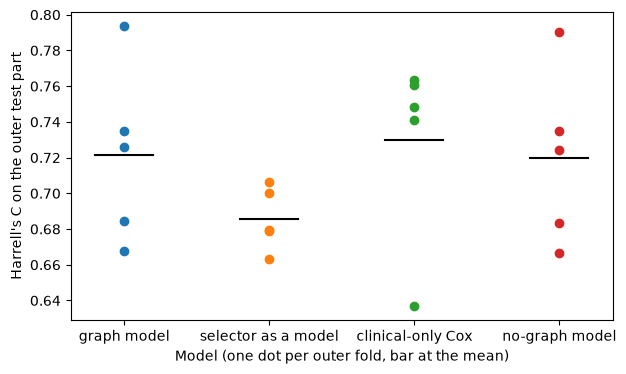

The graph model runs from 0.668 to 0.794 across the folds, while the row means lie within 0.044 of each other.

In [45]:
figure, axis = plt.subplots(figsize=(7, 4))
for position, model_name in enumerate(long_table["model"].unique()):
    scores = long_table.loc[long_table["model"] == model_name, "Harrell's C"]
    axis.plot([position] * len(scores), scores, "o", label=model_name)
    axis.plot([position - 0.2, position + 0.2], [scores.mean()] * 2, color="black")
axis.set_xticks(range(long_table["model"].nunique()), long_table["model"].unique())
axis.set_ylabel("Harrell's C on the outer test part")
axis.set_xlabel("Model (one dot per outer fold, bar at the mean)")
plt.show()
graph_scores = long_table.loc[long_table["model"] == "graph model", "Harrell's C"]
row_means = long_table.groupby("model")["Harrell's C"].mean()
display(Markdown(f"The graph model runs from {graph_scores.min():.3f} to {graph_scores.max():.3f} "
                 f"across the folds, while the row means lie within "
                 f"{row_means.max() - row_means.min():.3f} of each other."))

## Comparison rows

The comparison rows reuse each fold's split, inner folds and selector setting from its saved file; the fold's recorded scores are never read. Three plain networks (clinical only, genes only, genes plus clinical) and three graph variants (STRING 400, a learnable gene identity at 700, both) each choose their width and dropout on the same inner folds. The selector plus the clinical covariates runs its own stage A on the same paths. The control without edges takes the gene-identity row's genes, width, dropout and seed.

First the graphs themselves: how many STRING edges each fold's gene list has at score 700 and at 400, and the mean number of edges per gene. The same table gives the edges a random list of the same size would have, drawn from the genes the selector could choose in that fold, those passing the expression filter on its outer training part.

In [46]:
def edge_counts(genes, edge_table):
    """Edges among the given genes and the mean number of edges per gene."""
    kept = edges_among(genes, edge_table)
    return len(kept), round(2 * len(kept) / len(genes), 2)


rows = []
fold_genes = {}
for record in fold_records:
    genes = (RESULTS / f"outer_fold_{record['fold']}_genes.txt").read_text().split()
    fold_genes[record["fold"]] = genes
    edges_700, degree_700 = edge_counts(genes, edges)
    edges_400, degree_400 = edge_counts(genes, denser_edges)
    row = {"outer fold": record["fold"], "genes": len(genes), "edges at 700": edges_700,
           "mean degree at 700": degree_700, "edges at 400": edges_400,
           "mean degree at 400": degree_400}
    rows.append(row)
edge_table = pd.DataFrame(rows).set_index("outer fold")
edge_table.to_csv(RESULTS / "graph_question_edges.csv")

In [47]:
candidates = {}
expected_rows = []
for record in fold_records:
    fold = record["fold"]
    train = table.iloc[outer[fold - 1][0]]
    assert len(train) == record["patients"]["training"], "the split differs from the saved fold"
    expressed = (train[GENES] >= EXPRESSED_AT).mean() >= EXPRESSED_IN  # the filter of the fold
    candidates[fold] = list(expressed.index[expressed])
    assert set(fold_genes[fold]) <= set(candidates[fold]), "a selected gene is not a candidate"
    list_size, pool_size = len(fold_genes[fold]), len(candidates[fold])
    share = list_size * (list_size - 1) / (pool_size * (pool_size - 1))  # pairs in list / in pool
    row = {"outer fold": fold, "candidate genes": pool_size}
    for label, edge_list in [("700", edges), ("400", denser_edges)]:
        among_candidates = len(edges_among(candidates[fold], edge_list))
        row[f"edges among candidates at {label}"] = among_candidates
        row[f"expected for a random list at {label}"] = round(share * among_candidates, 1)
    expected_rows.append(row)
expected_table = pd.DataFrame(expected_rows).set_index("outer fold")
expected_table.to_csv(RESULTS / "graph_question_expected_edges.csv")
side_by_side = edge_table.join(expected_table)
side_by_side[["genes", "edges at 700", "expected for a random list at 700", "mean degree at 700",
              "edges at 400", "expected for a random list at 400", "mean degree at 400"]]

,genes,edges at 700,expected for a random list at 700,mean degree at 700,edges at 400,expected for a random list at 400,mean degree at 400
outer fold,,,,,,,
1,300,63,89.4,0.42,243,336.5,1.62
2,198,24,38.9,0.24,98,146.5,0.99
3,472,153,221.4,0.65,663,833.6,2.81
4,481,144,230.2,0.60,588,866.4,2.44
5,476,142,225.1,0.60,617,847.8,2.59


In [48]:
ratio_700 = edge_table["edges at 700"] / expected_table["expected for a random list at 700"]
ratio_400 = edge_table["edges at 400"] / expected_table["expected for a random list at 400"]
display(Markdown(f"The selected lists carry {ratio_700.min():.2f} to {ratio_700.max():.2f} times "
                 f"the edges a random list of the same size would carry at 700, and "
                 f"{ratio_400.min():.2f} to {ratio_400.max():.2f} times at 400; a ratio below 1 "
                 "means the selection keeps fewer connected genes than chance."))

The selected lists carry 0.62 to 0.70 times the edges a random list of the same size would carry at 700, and 0.67 to 0.80 times at 400; a ratio below 1 means the selection keeps fewer connected genes than chance.

A graph the selection cannot empty would add to each selected gene its STRING neighbours at 700 among the same candidates. The table counts the nodes and edges of such a graph with every neighbour and with at most the 5 strongest per gene, and a rough time per fold scaled from the registered run by the number of nodes; nothing is trained here.

In [49]:
def with_neighbours(genes, candidate_edges, kept=None):
    """The selected genes plus their STRING neighbours among the candidates, strongest first."""
    forward = {"gene_a": "gene", "gene_b": "neighbour"}
    backward = {"gene_b": "gene", "gene_a": "neighbour"}
    both_ways = pd.concat([candidate_edges.rename(columns=forward),
                           candidate_edges.rename(columns=backward)])
    around = both_ways[both_ways["gene"].isin(genes)]
    around = around.sort_values(["gene", "score", "neighbour"], ascending=[True, False, True])
    if kept is not None:
        around = around.groupby("gene").head(kept)
    return sorted(set(genes) | set(around["neighbour"]))


neighbour_rows = []
for record in fold_records:
    genes = fold_genes[record["fold"]]
    candidate_edges = edges_among(candidates[record["fold"]], edges)
    every = with_neighbours(genes, candidate_edges)
    strongest = with_neighbours(genes, candidate_edges, NEIGHBOURS_KEPT)
    strongest_edges = len(edges_among(strongest, candidate_edges))
    minutes = record["minutes"]["stage B"] + record["minutes"]["stage C"]
    row = {"outer fold": record["fold"], "genes": len(genes), "nodes, every neighbour": len(every),
           "edges, every neighbour": len(edges_among(every, candidate_edges)),
           f"nodes, at most {NEIGHBOURS_KEPT} per gene": len(strongest),
           f"edges, at most {NEIGHBOURS_KEPT} per gene": strongest_edges,
           "minutes now, stages B and C": round(minutes, 1),
           f"minutes estimated, at most {NEIGHBOURS_KEPT} per gene":
               round(minutes * len(strongest) / len(genes))}
    neighbour_rows.append(row)
neighbour_table = pd.DataFrame(neighbour_rows).set_index("outer fold")
neighbour_table.to_csv(RESULTS / "graph_question_neighbourhood.csv")
neighbour_table

,genes,"nodes, every neighbour","edges, every neighbour","nodes, at most 5 per gene","edges, at most 5 per gene","minutes now, stages B and C","minutes estimated, at most 5 per gene"
outer fold,,,,,,,
1,300,4093,95659,1248,6630,15.8,66
2,198,3064,66118,855,3858,10.1,44
3,472,5462,123041,1897,13977,20.1,81
4,481,5341,121542,1900,13642,25.9,102
5,476,5575,125320,1832,13020,28.0,108


In [50]:
kept_nodes = neighbour_table[f"nodes, at most {NEIGHBOURS_KEPT} per gene"]
kept_edges = neighbour_table[f"edges, at most {NEIGHBOURS_KEPT} per gene"]
hours_now = neighbour_table["minutes now, stages B and C"].sum() / 60
hours_kept = neighbour_table[f"minutes estimated, at most {NEIGHBOURS_KEPT} per gene"].sum() / 60
display(Markdown(f"With at most {NEIGHBOURS_KEPT} neighbours per gene the graphs would hold "
                 f"{kept_nodes.min()} to {kept_nodes.max()} genes and {kept_edges.min()} to "
                 f"{kept_edges.max()} edges, and stages B and C would take roughly "
                 f"{hours_kept:.0f} hours against {hours_now:.1f} now, if the time grows with the "
                 "number of nodes."))

With at most 5 neighbours per gene the graphs would hold 855 to 1900 genes and 3858 to 13977 edges, and stages B and C would take roughly 7 hours against 1.7 now, if the time grows with the number of nodes.

The selector plus the clinical covariates runs its own stage A under the same floor of 10 genes, so it can never drop every gene. The table gives, per fold, its best setting over all 75 candidates, the genes that setting keeps in the inner fit parts, and the eligible setting it chose; a best setting below the floor means that its inner folds preferred the clinical columns with almost no gene.

In [51]:
def floor_check(number):
    """The selector plus clinical covariates' best and chosen settings in one outer fold."""
    saved_row = json.loads(row_file("selector plus clinical covariates", number).read_text())
    grid = pd.DataFrame(saved_row["stage A"]["settings"])
    best = grid.sort_values(["inner mean C", "place"], ascending=[False, True]).iloc[0]
    yes_or_no = {True: "yes", False: "no"}
    row = {"outer fold": number, "best inner mean C": round(best["inner mean C"], 3),
           "best setting's fewest genes": int(best["fewest genes"]),
           "best setting eligible": yes_or_no[bool(best["eligible"])],
           "chosen inner mean C": round(saved_row["stage A"]["inner mean C"], 3),
           "genes kept on the outer part": saved_row["genes"]}
    return row


floor_rows = []
for number in range(1, OUTER_FOLDS + 1):
    if row_file("selector plus clinical covariates", number).exists():
        floor_rows.append(floor_check(number))
floor_table = pd.DataFrame(floor_rows)
if floor_rows:
    floor_table = floor_table.set_index("outer fold")
    floor_table.to_csv(RESULTS / "selector_plus_clinical_floor.csv")
    below = int((floor_table["best setting's fewest genes"] < LIST_MIN).sum())
    display(floor_table, Markdown(f"In {below} of {len(floor_table)} folds the best setting "
                                  f"keeps fewer than {LIST_MIN} genes in some inner fit part."))

,best inner mean C,best setting's fewest genes,best setting eligible,chosen inner mean C,genes kept on the outer part
outer fold,,,,,
1,0.773,50,yes,0.773,57
2,0.760,91,yes,0.760,126
3,0.769,0,no,0.759,14
4,0.731,0,no,0.712,27
5,0.750,0,no,0.749,65


In 3 of 5 folds the best setting keeps fewer than 10 genes in some inner fit part.

### Harrell's C on the outer test parts

The comparison rows that have a saved file for every fold join the registered rows, with the mean and standard deviation over the folds: first the registered and first comparison rows, then the layer rows added after the code review, then the rows that also choose their learning rate.

In [52]:
comparison_rows = []
for path in sorted(ROW_DIR.glob("*/outer_fold_*.json")) if ROW_DIR.exists() else []:
    record = json.loads(path.read_text())
    row = {"outer fold": record["fold"], "model": record["row"], "genes": record["genes"],
           **record["scores"]}
    comparison_rows.append(row)
comparison_table = pd.DataFrame(comparison_rows, columns=["outer fold", "model", "genes",
                                                          "Harrell's C", "Uno's C (5 years)"])
complete = comparison_table.groupby("model")["outer fold"].count()
complete_rows = list(complete.index[complete == len(fold_records)])
all_rows = pd.concat([long_table, comparison_table[comparison_table["model"].isin(complete_rows)]])
all_rows.to_csv(RESULTS / "comparison_by_fold.csv", index=False)
question_table = all_rows.pivot(index="outer fold", columns="model",
                                values=["Harrell's C", "Uno's C (5 years)"])
question_table.loc["mean"] = question_table.mean()
question_table.loc["SD"] = question_table.iloc[:-1].std()
earlier_rows = list(long_table["model"].unique()) + list(COMPARISON_ROWS)
harrell_by_row = question_table["Harrell's C"].T  # one model per line
display(harrell_by_row[harrell_by_row.index.isin(earlier_rows)].round(3))
later_rows = harrell_by_row[~harrell_by_row.index.isin(earlier_rows)].round(3)
rate_chosen = later_rows.index.str.contains("learning rate chosen")
display(later_rows[~rate_chosen])
display(later_rows[rate_chosen])
harrell_means = question_table.loc["mean", "Harrell's C"]
display(Markdown(f"{len(complete_rows)} comparison rows have all {len(fold_records)} folds; the "
                 f"row means run from {harrell_means.min():.3f} ({harrell_means.idxmin()}) to "
                 f"{harrell_means.max():.3f} ({harrell_means.idxmax()})."))

outer fold,1,2,3,4,5,mean,SD
model,,,,,,,
clinical MLP,0.729,0.695,0.663,0.797,0.708,0.718,0.050
clinical-only Cox,0.763,0.748,0.637,0.741,0.761,0.730,0.053
gene MLP,0.642,0.630,0.609,0.664,0.695,0.648,0.033
gene plus clinical MLP,0.711,0.671,0.657,0.707,0.703,0.690,0.024
graph model,0.735,0.685,0.668,0.794,0.726,0.721,0.049
"graph model, STRING 400",0.751,0.670,0.639,0.793,0.724,0.715,0.062
"graph model, STRING 400, gene identity",0.737,0.676,0.678,0.803,0.716,0.722,0.052
"graph model, STRING 700, gene identity",0.727,0.694,0.670,0.802,0.722,0.723,0.050
no-graph model,0.735,0.684,0.667,0.790,0.725,0.720,0.048


outer fold,1,2,3,4,5,mean,SD
model,,,,,,,
"GATv2, STRING 400",0.733,0.711,0.664,0.796,0.713,0.723,0.048
"GATv2, STRING 400, edges removed",0.729,0.716,0.667,0.794,0.713,0.724,0.046
"GATv2, STRING 700",0.732,0.699,0.658,0.794,0.714,0.719,0.050
"GATv2, STRING 700, edges removed",0.733,0.703,0.663,0.794,0.713,0.721,0.048
"GCN, STRING 400",0.739,0.701,0.653,0.790,0.720,0.721,0.050
"GCN, STRING 400, edges removed",0.744,0.705,0.650,0.791,0.717,0.721,0.052
"GCN, STRING 700",0.743,0.715,0.647,0.790,0.719,0.723,0.052
"GCN, STRING 700, edges removed",0.744,0.716,0.650,0.791,0.717,0.724,0.051
"GIN, STRING 400",0.751,0.685,0.660,0.796,0.695,0.718,0.055


outer fold,1,2,3,4,5,mean,SD
model,,,,,,,
"GCN, STRING 400, learning rate chosen",0.784,0.718,0.648,0.758,0.791,0.740,0.059
"GCN, STRING 400, learning rate chosen, edges removed",0.780,0.715,0.656,0.752,0.796,0.740,0.056
"GIN, STRING 400, learning rate chosen",0.783,0.706,0.600,0.752,0.772,0.722,0.075
"GIN, STRING 400, learning rate chosen, edges removed",0.770,0.727,0.642,0.740,0.789,0.734,0.057
"GraphSAGE, STRING 400, learning rate chosen",0.769,0.701,0.637,0.763,0.758,0.725,0.057
"GraphSAGE, STRING 400, learning rate chosen, edges removed",0.769,0.707,0.634,0.745,0.803,0.731,0.065
"GraphSAGE, STRING 700, learning rate chosen",0.775,0.703,0.642,0.766,0.799,0.737,0.064
"GraphSAGE, STRING 700, learning rate chosen, edges removed",0.769,0.709,0.634,0.771,0.795,0.735,0.065


32 comparison rows have all 5 folds; the row means run from 0.648 (gene MLP) to 0.740 (GCN, STRING 400, learning rate chosen).

### Uno's C up to five years

The same rows on Uno's C, the secondary score, which reweights the patient pairs for censoring and is read up to five years.

In [53]:
uno_by_row = question_table["Uno's C (5 years)"].T  # one model per line
display(uno_by_row[uno_by_row.index.isin(earlier_rows)].round(3))
later_uno = uno_by_row[~uno_by_row.index.isin(earlier_rows)].round(3)
display(later_uno[~later_uno.index.str.contains("learning rate chosen")])
display(later_uno[later_uno.index.str.contains("learning rate chosen")])
uno_means = question_table.loc["mean", "Uno's C (5 years)"]
wide_uno = all_rows.pivot(index="outer fold", columns="model", values="Uno's C (5 years)")
uno_pair = paired_interval(wide_uno, "graph model", "clinical-only Cox")
display(Markdown(f"On Uno's C the row means run from {uno_means.min():.3f} "
                 f"({uno_means.idxmin()}) to {uno_means.max():.3f} ({uno_means.idxmax()}). The "
                 f"registered comparison on Uno's C, graph model minus clinical-only Cox, is "
                 f"{uno_pair['mean difference']:+.3f} (interval {uno_pair['lower']:+.3f} to "
                 f"{uno_pair['upper']:+.3f}); no other interval is computed on the secondary "
                 "score."))

outer fold,1,2,3,4,5,mean,SD
model,,,,,,,
clinical MLP,0.741,0.618,0.670,0.783,0.659,0.694,0.066
clinical-only Cox,0.778,0.673,0.666,0.726,0.687,0.706,0.047
gene MLP,0.673,0.640,0.601,0.687,0.711,0.662,0.043
gene plus clinical MLP,0.718,0.696,0.633,0.746,0.704,0.699,0.042
graph model,0.741,0.660,0.681,0.798,0.697,0.715,0.055
"graph model, STRING 400",0.754,0.627,0.645,0.794,0.697,0.704,0.071
"graph model, STRING 400, gene identity",0.751,0.650,0.701,0.802,0.672,0.715,0.061
"graph model, STRING 700, gene identity",0.740,0.659,0.682,0.801,0.682,0.713,0.058
no-graph model,0.747,0.653,0.678,0.793,0.696,0.713,0.056


outer fold,1,2,3,4,5,mean,SD
model,,,,,,,
"GATv2, STRING 400",0.751,0.663,0.681,0.795,0.712,0.720,0.054
"GATv2, STRING 400, edges removed",0.746,0.665,0.681,0.794,0.682,0.714,0.054
"GATv2, STRING 700",0.744,0.664,0.678,0.794,0.688,0.714,0.054
"GATv2, STRING 700, edges removed",0.747,0.669,0.680,0.794,0.682,0.714,0.054
"GCN, STRING 400",0.758,0.656,0.670,0.789,0.697,0.714,0.057
"GCN, STRING 400, edges removed",0.759,0.658,0.663,0.790,0.695,0.713,0.059
"GCN, STRING 700",0.759,0.653,0.664,0.789,0.695,0.712,0.060
"GCN, STRING 700, edges removed",0.759,0.655,0.663,0.790,0.695,0.713,0.060
"GIN, STRING 400",0.751,0.634,0.681,0.798,0.644,0.702,0.071


outer fold,1,2,3,4,5,mean,SD
model,,,,,,,
"GCN, STRING 400, learning rate chosen",0.828,0.676,0.683,0.729,0.732,0.730,0.061
"GCN, STRING 400, learning rate chosen, edges removed",0.819,0.674,0.691,0.723,0.744,0.730,0.057
"GIN, STRING 400, learning rate chosen",0.779,0.632,0.648,0.721,0.701,0.696,0.059
"GIN, STRING 400, learning rate chosen, edges removed",0.788,0.683,0.673,0.718,0.734,0.719,0.046
"GraphSAGE, STRING 400, learning rate chosen",0.782,0.646,0.676,0.737,0.692,0.707,0.053
"GraphSAGE, STRING 400, learning rate chosen, edges removed",0.791,0.653,0.673,0.721,0.760,0.720,0.058
"GraphSAGE, STRING 700, learning rate chosen",0.784,0.678,0.682,0.749,0.752,0.729,0.047
"GraphSAGE, STRING 700, learning rate chosen, edges removed",0.791,0.659,0.673,0.754,0.739,0.723,0.056


On Uno's C the row means run from 0.662 (gene MLP) to 0.736 (selector plus clinical covariates). The registered comparison on Uno's C, graph model minus clinical-only Cox, is +0.009 (interval -0.067 to +0.085); no other interval is computed on the secondary score.

### Paired differences

Each difference is taken fold by fold on the same test parts, with the corrected resampled t interval of the registered comparison. The questions: does a row beat the clinical-only Cox; do the edges change the score against the same model without them; do gene identity or a denser graph change it, where the two STRING 400 rows sit because they chose their own width and dropout while their controls kept the 700 settings; and do the plain networks differ. The questions of the rows added after the review follow.

In [54]:
PAIRED_GROUPS = {
    "do the edges change the score": [
        ("graph model", "no-graph model"),
        (IDENTITY_700, "no-graph model, gene identity")],
    "do gene identity or a denser graph change it": [
        (IDENTITY_700, "graph model"),
        ("graph model, STRING 400, gene identity", "graph model, STRING 400"),
        ("graph model, STRING 400", "graph model"),
        ("no-graph model, gene identity", "no-graph model"),
        ("graph model, STRING 400", "no-graph model"),
        ("graph model, STRING 400, gene identity", "no-graph model, gene identity")],
    "do the plain networks differ": [
        ("graph model", "gene plus clinical MLP"),
        ("gene plus clinical MLP", "clinical MLP"),
        ("gene MLP", "selector as a model"),
        ("gene plus clinical MLP", "selector plus clinical covariates")],
    "does the GPU reproduce the registered rows": [
        ("GraphSAGE, STRING 700", "graph model"),
        ("GraphSAGE, STRING 400", "graph model, STRING 400")],
    "does the layer type change the score": [],
    "do the edges change the score of each layer type": [],
    "does choosing the learning rate change the score": []}

In [55]:
for layer in GRAPH_LAYERS[1:]:
    for label in ["STRING 700", "STRING 400"]:
        pair = (f"{layer}, {label}", f"GraphSAGE, {label}")
        PAIRED_GROUPS["does the layer type change the score"].append(pair)
for rows_of_one_kind in [LAYER_ROWS, RATE_ROWS]:
    for name, variant in rows_of_one_kind.items():
        if "settings from" in variant:
            pair = (variant["settings from"], name)
            PAIRED_GROUPS["do the edges change the score of each layer type"].append(pair)
for name, variant in RATE_ROWS.items():
    if "settings from" not in variant:
        pair = (name, name.replace(", learning rate chosen", ""))
        PAIRED_GROUPS["does choosing the learning rate change the score"].append(pair)
PAIRED_GROUPS["does a row beat the clinical-only Cox"] = []
PAIRED_GROUPS["does a row added after the review beat the clinical-only Cox"] = []
for name in all_rows["model"].unique():
    if name in earlier_rows and name != "clinical-only Cox":
        PAIRED_GROUPS["does a row beat the clinical-only Cox"].append((name, "clinical-only Cox"))
    if name not in earlier_rows:
        pair = (name, "clinical-only Cox")
        PAIRED_GROUPS["does a row added after the review beat the clinical-only Cox"].append(pair)

In [56]:
wide_all = all_rows.pivot(index="outer fold", columns="model", values="Harrell's C")
pair_rows = []
for group, pairs in PAIRED_GROUPS.items():
    for first, second in pairs:
        if first in wide_all.columns and second in wide_all.columns:
            result = paired_interval(wide_all, first, second)
            result["question"] = group
            pair_rows.append(result)
question_pairs = pd.DataFrame(pair_rows).set_index("comparison")
question_pairs["includes 0"] = (question_pairs["lower"] <= 0) & (question_pairs["upper"] >= 0)
yes_or_no = {True: "yes", False: "no"}
question_pairs["includes 0"] = question_pairs["includes 0"].map(yes_or_no)
question_pairs.to_csv(RESULTS / "comparison_paired.csv")


def pair_group(group):
    """The paired comparisons that answer one question, rounded for reading."""
    chosen = question_pairs[question_pairs["question"] == group]
    return chosen[["mean difference", "lower", "upper", "includes 0"]].round(3)


def group_sentence(group):
    """How many intervals of one question include 0, the mean differences and the half-widths."""
    chosen = question_pairs[question_pairs["question"] == group]
    if chosen.empty:
        return "no interval is computed yet."
    half = chosen["upper"] - chosen["mean difference"]
    return (f"{int((chosen['includes 0'] == 'yes').sum())} of the {len(chosen)} intervals include "
            f"0; the mean differences run from {chosen['mean difference'].min():.3f} to "
            f"{chosen['mean difference'].max():.3f}, and the half-widths, the smallest difference "
            f"each interval could show, from {half.min():.3f} to {half.max():.3f}.")

In [57]:
excluding = int((question_pairs["includes 0"] == "no").sum())
verb = "excludes" if excluding == 1 else "exclude"
display(Markdown(f"{len(question_pairs)} intervals are read on the same five test parts and "
                 f"{excluding} {verb} 0. At the {CONFIDENCE:.0%} level about one interval in "
                 f"{round(1 / (1 - CONFIDENCE))} would exclude 0 by chance if no row differed, and "
                 "intervals that share test parts and reference rows are not independent "
                 "readings, so a single exclusion is not a finding on its own."))
display(pair_group("does a row beat the clinical-only Cox"))
display(Markdown("Against the clinical-only Cox: "
                 + group_sentence("does a row beat the clinical-only Cox")))

71 intervals are read on the same five test parts and 2 exclude 0. At the 95% level about one interval in 20 would exclude 0 by chance if no row differed, and intervals that share test parts and reference rows are not independent readings, so a single exclusion is not a finding on its own.

,mean difference,lower,upper,includes 0
comparison,,,,
graph model minus clinical-only Cox,-0.009,-0.099,0.082,yes
selector as a model minus clinical-only Cox,-0.044,-0.143,0.054,yes
no-graph model minus clinical-only Cox,-0.010,-0.099,0.079,yes
clinical MLP minus clinical-only Cox,-0.012,-0.105,0.081,yes
gene MLP minus clinical-only Cox,-0.082,-0.155,-0.010,no
gene plus clinical MLP minus clinical-only Cox,-0.040,-0.110,0.029,yes
"graph model, STRING 400 minus clinical-only Cox",-0.015,-0.104,0.075,yes
"graph model, STRING 400, gene identity minus clinical-only Cox",-0.008,-0.115,0.098,yes
"graph model, STRING 700, gene identity minus clinical-only Cox",-0.007,-0.101,0.087,yes


Against the clinical-only Cox: 10 of the 11 intervals include 0; the mean differences run from -0.082 to 0.009, and the half-widths, the smallest difference each interval could show, from 0.053 to 0.107.

In [58]:
edge_effects = pair_group("do the edges change the score")
display(edge_effects)
plain_bound = edge_effects.loc["graph model minus no-graph model"]
identity_bound = edge_effects.loc[f"{IDENTITY_700} minus no-graph model, gene identity"]
display(Markdown(f"At score 700 the edges change Harrell's C by {plain_bound['lower']:+.3f} to "
                 f"{plain_bound['upper']:+.3f} without gene identity and by "
                 f"{identity_bound['lower']:+.3f} to {identity_bound['upper']:+.3f} with it. "
                 + group_sentence("do the edges change the score")))

,mean difference,lower,upper,includes 0
comparison,,,,
graph model minus no-graph model,0.001,-0.001,0.004,yes
"graph model, STRING 700, gene identity minus no-graph model, gene identity",-0.000,-0.005,0.004,yes


At score 700 the edges change Harrell's C by -0.001 to +0.004 without gene identity and by -0.005 to +0.004 with it. 2 of the 2 intervals include 0; the mean differences run from -0.000 to 0.001, and the half-widths, the smallest difference each interval could show, from 0.002 to 0.005.

In [59]:
display(pair_group("do gene identity or a denser graph change it"))
display(Markdown("Gene identity and graph density: "
                 + group_sentence("do gene identity or a denser graph change it")))

,mean difference,lower,upper,includes 0
comparison,,,,
"graph model, STRING 700, gene identity minus graph model",0.002,-0.012,0.015,yes
"graph model, STRING 400, gene identity minus graph model, STRING 400",0.007,-0.032,0.045,yes
"graph model, STRING 400 minus graph model",-0.006,-0.038,0.025,yes
"no-graph model, gene identity minus no-graph model",0.003,-0.015,0.022,yes
"graph model, STRING 400 minus no-graph model",-0.005,-0.036,0.027,yes
"graph model, STRING 400, gene identity minus no-graph model, gene identity",-0.002,-0.025,0.022,yes


Gene identity and graph density: 6 of the 6 intervals include 0; the mean differences run from -0.006 to 0.007, and the half-widths, the smallest difference each interval could show, from 0.014 to 0.039.

In [60]:
display(pair_group("do the plain networks differ"))
display(Markdown("Plain networks: " + group_sentence("do the plain networks differ")))

,mean difference,lower,upper,includes 0
comparison,,,,
graph model minus gene plus clinical MLP,0.032,-0.027,0.090,yes
gene plus clinical MLP minus clinical MLP,-0.029,-0.095,0.038,yes
gene MLP minus selector as a model,-0.038,-0.081,0.005,yes
gene plus clinical MLP minus selector plus clinical covariates,-0.050,-0.152,0.053,yes


Plain networks: 4 of the 4 intervals include 0; the mean differences run from -0.050 to 0.032, and the half-widths, the smallest difference each interval could show, from 0.043 to 0.102.

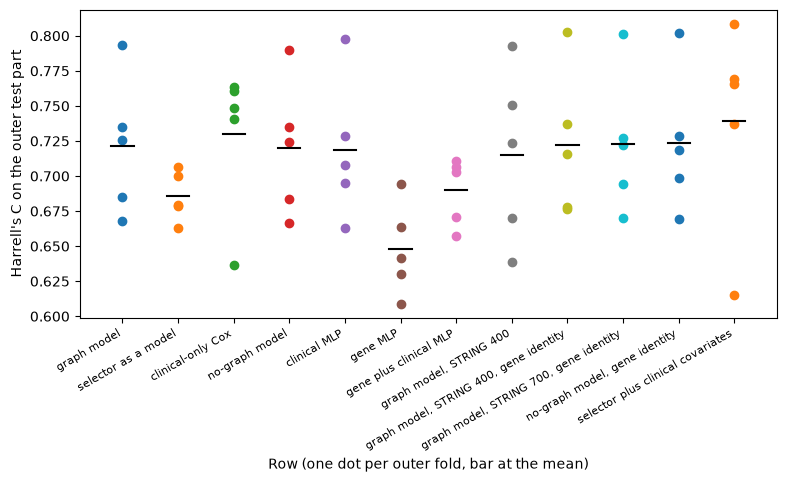

The row means lie between 0.648 and 0.740, while each row's folds span 0.043 to 0.193.

In [61]:
figure, axis = plt.subplots(figsize=(9, 4))
earlier_in_table = all_rows[all_rows["model"].isin(earlier_rows)]
for position, model_name in enumerate(earlier_in_table["model"].unique()):
    scores = earlier_in_table.loc[earlier_in_table["model"] == model_name, "Harrell's C"]
    axis.plot([position] * len(scores), scores, "o")
    axis.plot([position - 0.2, position + 0.2], [scores.mean()] * 2, color="black")
axis.set_xticks(range(earlier_in_table["model"].nunique()), earlier_in_table["model"].unique(),
                rotation=30, ha="right", fontsize=8)
axis.set_ylabel("Harrell's C on the outer test part")
axis.set_xlabel("Row (one dot per outer fold, bar at the mean)")
plt.show()
spans = all_rows.groupby("model")["Harrell's C"].agg(lambda scores: scores.max() - scores.min())
display(Markdown(f"The row means lie between {harrell_means.min():.3f} and "
                 f"{harrell_means.max():.3f}, while each row's folds span {spans.min():.3f} to "
                 f"{spans.max():.3f}."))

### The layer types

GraphSAGE recomputed on the GPU is the reference for the three other layer types at the same cut-off, and each layer row is compared with its own control without edges. At STRING 700 most selected genes have no edge, and a node without neighbours gives the same function of its feature in every layer type, so a difference there was not expected; at 400 most selected genes have an edge.

In [62]:
display(pair_group("does the GPU reproduce the registered rows"))
display(Markdown("GPU against the registered CPU rows: "
                 + group_sentence("does the GPU reproduce the registered rows")))
display(pair_group("does the layer type change the score"))
display(Markdown("Layer type against GraphSAGE: "
                 + group_sentence("does the layer type change the score")))

,mean difference,lower,upper,includes 0
comparison,,,,
"GraphSAGE, STRING 700 minus graph model",-0.001,-0.013,0.011,yes
"GraphSAGE, STRING 400 minus graph model, STRING 400",0.006,-0.018,0.029,yes


GPU against the registered CPU rows: 2 of the 2 intervals include 0; the mean differences run from -0.001 to 0.006, and the half-widths, the smallest difference each interval could show, from 0.012 to 0.024.

,mean difference,lower,upper,includes 0
comparison,,,,
"GCN, STRING 700 minus GraphSAGE, STRING 700",0.002,-0.038,0.043,yes
"GCN, STRING 400 minus GraphSAGE, STRING 400",-0.000,-0.035,0.034,yes
"GIN, STRING 700 minus GraphSAGE, STRING 700",-0.002,-0.027,0.023,yes
"GIN, STRING 400 minus GraphSAGE, STRING 400",-0.003,-0.037,0.030,yes
"GATv2, STRING 700 minus GraphSAGE, STRING 700",-0.001,-0.027,0.025,yes
"GATv2, STRING 400 minus GraphSAGE, STRING 400",0.002,-0.041,0.046,yes


Layer type against GraphSAGE: 6 of the 6 intervals include 0; the mean differences run from -0.003 to 0.002, and the half-widths, the smallest difference each interval could show, from 0.025 to 0.043.

In [63]:
display(pair_group("do the edges change the score of each layer type"))
display(Markdown("Edges within each layer type: "
                 + group_sentence("do the edges change the score of each layer type")))
after_review = pair_group("does a row added after the review beat the clinical-only Cox")
display(after_review[~after_review.index.str.contains("learning rate chosen")])
display(after_review[after_review.index.str.contains("learning rate chosen")])
display(Markdown("Against the clinical-only Cox: "
                 + group_sentence("does a row added after the review beat the clinical-only Cox")))

,mean difference,lower,upper,includes 0
comparison,,,,
"GraphSAGE, STRING 700 minus GraphSAGE, STRING 700, edges removed",0.000,-0.005,0.005,yes
"GraphSAGE, STRING 400 minus GraphSAGE, STRING 400, edges removed",0.002,-0.007,0.010,yes
"GCN, STRING 700 minus GCN, STRING 700, edges removed",-0.001,-0.004,0.003,yes
"GCN, STRING 400 minus GCN, STRING 400, edges removed",-0.001,-0.008,0.006,yes
"GIN, STRING 700 minus GIN, STRING 700, edges removed",-0.004,-0.008,-0.000,no
"GIN, STRING 400 minus GIN, STRING 400, edges removed",0.001,-0.033,0.035,yes
"GATv2, STRING 700 minus GATv2, STRING 700, edges removed",-0.002,-0.007,0.004,yes
"GATv2, STRING 400 minus GATv2, STRING 400, edges removed",-0.000,-0.007,0.006,yes
"GraphSAGE, STRING 700, learning rate chosen minus GraphSAGE, STRING 700, learning rate chosen, edges removed",0.002,-0.011,0.014,yes


Edges within each layer type: 11 of the 12 intervals include 0; the mean differences run from -0.011 to 0.002, and the half-widths, the smallest difference each interval could show, from 0.004 to 0.044.

,mean difference,lower,upper,includes 0
comparison,,,,
"GATv2, STRING 400 minus clinical-only Cox",-0.007,-0.091,0.077,yes
"GATv2, STRING 400, edges removed minus clinical-only Cox",-0.006,-0.090,0.077,yes
"GATv2, STRING 700 minus clinical-only Cox",-0.011,-0.096,0.074,yes
"GATv2, STRING 700, edges removed minus clinical-only Cox",-0.009,-0.094,0.076,yes
"GCN, STRING 400 minus clinical-only Cox",-0.009,-0.086,0.067,yes
"GCN, STRING 400, edges removed minus clinical-only Cox",-0.009,-0.084,0.067,yes
"GCN, STRING 700 minus clinical-only Cox",-0.007,-0.076,0.062,yes
"GCN, STRING 700, edges removed minus clinical-only Cox",-0.006,-0.078,0.065,yes
"GIN, STRING 400 minus clinical-only Cox",-0.012,-0.111,0.087,yes


,mean difference,lower,upper,includes 0
comparison,,,,
"GCN, STRING 400, learning rate chosen minus clinical-only Cox",0.010,-0.034,0.053,yes
"GCN, STRING 400, learning rate chosen, edges removed minus clinical-only Cox",0.010,-0.038,0.058,yes
"GIN, STRING 400, learning rate chosen minus clinical-only Cox",-0.007,-0.063,0.048,yes
"GIN, STRING 400, learning rate chosen, edges removed minus clinical-only Cox",0.004,-0.029,0.036,yes
"GraphSAGE, STRING 400, learning rate chosen minus clinical-only Cox",-0.005,-0.053,0.044,yes
"GraphSAGE, STRING 400, learning rate chosen, edges removed minus clinical-only Cox",0.001,-0.054,0.057,yes
"GraphSAGE, STRING 700, learning rate chosen minus clinical-only Cox",0.007,-0.053,0.067,yes
"GraphSAGE, STRING 700, learning rate chosen, edges removed minus clinical-only Cox",0.005,-0.049,0.060,yes


Against the clinical-only Cox: 24 of the 24 intervals include 0; the mean differences run from -0.013 to 0.010, and the half-widths, the smallest difference each interval could show, from 0.033 to 0.099.

In [64]:
if len(pair_group("does choosing the learning rate change the score")):
    display(pair_group("does choosing the learning rate change the score"))
    display(Markdown("Choosing the learning rate: "
                     + group_sentence("does choosing the learning rate change the score")))
else:
    display(Markdown("No learning-rate row was computed, as the training-curve rule decided."))

,mean difference,lower,upper,includes 0
comparison,,,,
"GraphSAGE, STRING 700, learning rate chosen minus GraphSAGE, STRING 700",0.017,-0.064,0.098,yes
"GraphSAGE, STRING 400, learning rate chosen minus GraphSAGE, STRING 400",0.005,-0.057,0.066,yes
"GCN, STRING 400, learning rate chosen minus GCN, STRING 400",0.019,-0.056,0.095,yes
"GIN, STRING 400, learning rate chosen minus GIN, STRING 400",0.005,-0.100,0.110,yes


Choosing the learning rate: 4 of the 4 intervals include 0; the mean differences run from 0.005 to 0.019, and the half-widths, the smallest difference each interval could show, from 0.061 to 0.105.

## Part 2: the final model

A plain five-fold cross-validation on all patients runs stage A then stage B once more to choose the final settings; the selector refitted on all patients, at the chosen place on their own path, gives the final gene list; the graph model is trained on all patients and frozen. These five folds are the outer split itself (same seed, same table), so the inner scores in the final record are not estimates of the final model.

In [65]:
final_dir = RESULTS / "final_model"
final_file = final_dir / "model.pt"
if COMPUTE and len(fold_records) == OUTER_FOLDS and not final_file.exists():
    final_dir.mkdir(exist_ok=True)
    started = time.time()
    all_inner = folds(table, INNER_FOLDS)
    setting, grid, per_fold = stage_a(table, all_inner)
    graph_setting, inner_table, few_genes = stage_b(table, all_inner, setting, BASE)
    final_genes, _, penalty = select_genes(table, table, setting)
    x_all, _ = scaled_expression(table, table)
    c_all, _ = clinical_vectors(table, table)
    inputs = model_inputs(BASE, x_all, final_genes, c_all)
    hidden = int(graph_setting["hidden size"])
    dropout = float(graph_setting["dropout"])
    model = train_network(new_model(BASE, inputs, hidden, dropout), inputs, table)
    frozen = {"state": model.state_dict(), "hidden size": hidden, "dropout": dropout,
              "genes": final_genes, "l1 ratio": float(setting["l1 ratio"]),
              "place": int(setting["place"]), "penalty": penalty,
              "clinical levels": {name: sorted(table[name].unique()) for name in CATEGORIES},
              "data sha256": data_hash, "edges sha256": edge_hash}
    torch.save(frozen, final_file)
    final_record = {"stage A": stage_a_record(setting, grid, per_fold),
                    "stage B": stage_b_record(graph_setting, inner_table, few_genes),
                    "genes": len(final_genes), "penalty": penalty,
                    "minutes": round((time.time() - started) / 60, 1),
                    "model sha256": hashlib.sha256(final_file.read_bytes()).hexdigest()}
    (final_dir / "final_record.json").write_text(json.dumps(final_record, indent=1))
    (final_dir / "final_genes.txt").write_text("\n".join(final_genes) + "\n")

In [66]:
if final_file.exists():
    final_record = json.loads((final_dir / "final_record.json").read_text())
    final_genes = (final_dir / "final_genes.txt").read_text().split()
    rows = []
    for record in fold_records:
        fold_list = set((RESULTS / f"outer_fold_{record['fold']}_genes.txt").read_text().split())
        overlap = len(fold_list & set(final_genes)) / len(fold_list | set(final_genes))
        row = {"outer fold": record["fold"], "genes": len(fold_list),
               "Jaccard overlap with the final list": round(overlap, 2)}
        rows.append(row)
    overlaps = pd.DataFrame(rows).set_index("outer fold")
    assert (overlaps["Jaccard overlap with the final list"] < 1).any(), "no fold list differs"
    final_values = {"L1 ratio": final_record["stage A"]["l1 ratio"],
                    "place on the path": final_record["stage A"]["place"],
                    "penalty": round(final_record["penalty"], 4),
                    "hidden size": final_record["stage B"]["hidden size"],
                    "dropout": final_record["stage B"]["dropout"],
                    "final genes": final_record["genes"],
                    "model file sha256": final_record["model sha256"][:16] + "...",
                    "minutes": final_record["minutes"]}
    final_table = pd.Series(final_values, name="final model").to_frame()
    final_table.to_csv(RESULTS / "final_settings.csv")
    overlaps.to_csv(RESULTS / "final_overlaps.csv")
    display(final_table, overlaps)
    jaccard = overlaps["Jaccard overlap with the final list"]
    display(Markdown(f"The final list of {final_record['genes']} genes has a Jaccard overlap of "
                     f"{jaccard.min():.2f} to {jaccard.max():.2f} with the five fold lists, the "
                     "shared genes divided by the genes in either list."))
else:
    display(Markdown("The final model is not yet trained."))

,final model
L1 ratio,0.5
place on the path,21
penalty,0.0096
hidden size,64
dropout,0.5
final genes,450
model file sha256,3fca65c483e0bed0...
minutes,29.8


,genes,Jaccard overlap with the final list
outer fold,,
1,300,0.30
2,198,0.22
3,472,0.40
4,481,0.33
5,476,0.33


The final list of 450 genes has a Jaccard overlap of 0.22 to 0.40 with the five fold lists, the shared genes divided by the genes in either list.

## Final models of the layer-type rows

For METABRIC every layer-type row gets its own final model the way the registered one was made: the registered final selector setting and gene list, the row's width and dropout chosen on the same five folds of all patients (a control takes its source's), training on all patients, frozen.

In [67]:
FINAL_DIR = RESULTS / "final_models"


def final_folder(name):
    """The folder of one row's final model."""
    return FINAL_DIR / name.replace(", ", "_").replace(" ", "_").lower()


def final_network_setting(variant, setting):
    """A row's final width, dropout and learning rate: chosen on all patients, or its source's."""
    if "settings from" in variant:
        source_file = final_folder(variant["settings from"]) / "final_record.json"
        return json.loads(source_file.read_text())["stage B"]
    all_inner = folds(table, INNER_FOLDS)
    network_setting, inner_table, few_genes = stage_b(table, all_inner, setting, variant)
    return stage_b_record(network_setting, inner_table, few_genes)

In [68]:
def train_final(name, variant, setting, genes):
    """Train one row's final model on every patient and freeze it with its record."""
    started = time.time()
    network_setting = final_network_setting(variant, setting)
    x_all, _ = scaled_expression(table, table)
    c_all, _ = clinical_vectors(table, table)
    inputs = model_inputs(variant, x_all, genes, c_all)
    hidden, dropout = network_setting["hidden size"], network_setting["dropout"]
    model = new_model(variant, inputs, hidden, dropout)
    model = train_network(model, inputs, table, network_setting["learning rate"])
    state = {}
    for key, value in model.state_dict().items():
        state[key] = value.cpu()
    frozen = {"state": state, "hidden size": hidden, "dropout": dropout,
              "learning rate": network_setting["learning rate"], "genes": genes,
              "layer": variant["layer"], "edges": len(edges_among(genes, variant["edges"])),
              "data sha256": data_hash, "device": DEVICE_NAME}
    final_folder(name).mkdir(parents=True, exist_ok=True)
    torch.save(frozen, final_folder(name) / "model.pt")
    model_hash = hashlib.sha256((final_folder(name) / "model.pt").read_bytes()).hexdigest()
    record = {"row": name, "stage B": network_setting, "genes": len(genes),
              "minutes": round((time.time() - started) / 60, 1), "model sha256": model_hash}
    (final_folder(name) / "final_record.json").write_text(json.dumps(record, indent=1))

In [69]:
final_rows = list(LAYER_ROWS.items())
if COMPUTE and final_file.exists():
    refit, _, _ = select_genes(table, table, final_record["stage A"])
    assert refit == final_genes, "the final selector setting gives another gene list"
    for name, variant in final_rows:
        if not (final_folder(name) / "model.pt").exists():
            train_final(name, variant, final_record["stage A"], final_genes)
final_rows_done = []
for name, variant in final_rows:
    if (final_folder(name) / "final_record.json").exists():
        record = json.loads((final_folder(name) / "final_record.json").read_text())
        row = {"row": name, "hidden size": record["stage B"]["hidden size"],
               "dropout": record["stage B"]["dropout"],
               "learning rate": record["stage B"]["learning rate"],
               "genes": record["genes"], "minutes": record["minutes"]}
        final_rows_done.append(row)
final_models_table = pd.DataFrame(final_rows_done)
display(Markdown(f"{len(final_models_table)} final models of layer-type rows are saved."))
if final_rows_done:
    final_models_table = final_models_table.set_index("row")
    final_models_table.to_csv(RESULTS / "final_models.csv")
    display(final_models_table)

16 final models of layer-type rows are saved.

,hidden size,dropout,learning rate,genes,minutes
row,,,,,
"GraphSAGE, STRING 700",64,0.5,0.001,450,1.6
"GraphSAGE, STRING 700, edges removed",64,0.5,0.001,450,0.1
"GraphSAGE, STRING 400",64,0.5,0.001,450,1.8
"GraphSAGE, STRING 400, edges removed",64,0.5,0.001,450,0.1
"GCN, STRING 700",64,0.5,0.001,450,1.9
"GCN, STRING 700, edges removed",64,0.5,0.001,450,0.1
"GCN, STRING 400",128,0.5,0.001,450,2.3
"GCN, STRING 400, edges removed",128,0.5,0.001,450,0.1
"GIN, STRING 700",128,0.2,0.001,450,1.5


## METABRIC, scored once

The external cohort is scored once with models fitted on every TCGA patient. The alignment was fixed on 5 November before the run: the clinical encoder and age scaler are TCGA's, METABRIC's stage 0 becomes stage I, each gene is z-scored on METABRIC itself because the two platforms measure on different scales, a missing expression value takes the gene's METABRIC median, and Uno's C weighs pairs by METABRIC's own censoring. Harrell's C on overall survival is primary; disease-specific survival is secondary.

In [70]:
METABRIC_DIR = RESULTS / "metabric"
PRIMARY = "Harrell's C, overall survival"


def aligned_metabric():
    """METABRIC as notebook 1 wrote it, aligned to the TCGA models, with the alignment counts."""
    metabric = pd.read_parquet(METABRIC_FILE)
    metabric_hash = hashlib.sha256(METABRIC_FILE.read_bytes()).hexdigest()
    assert metabric_hash == cohort_record["metabric"]["file sha256"], "not notebook 1's table"
    counts = {"patients": len(metabric), "deaths": int(metabric["os_event"].sum()),
              "missing expression values filled": int(metabric[GENES].isna().sum().sum()),
              "stage 0 patients mapped": int((metabric["stage"] == "0").sum())}
    metabric[GENES] = metabric[GENES].fillna(metabric[GENES].median())
    metabric["stage"] = metabric["stage"].replace("0", METABRIC_STAGE_0)
    metabric = metabric.join(pd.read_parquet(METABRIC_CAUSE_FILE))
    known = metabric["death from the disease"].notna()
    counts["disease-specific endpoint: patients"] = int(known.sum())
    counts["disease-specific endpoint: deaths"] = int(metabric["death from the disease"].sum())
    return metabric, counts


def metabric_genes(metabric, genes):
    """METABRIC expression of some genes, z-scored on METABRIC itself."""
    values = StandardScaler().fit_transform(metabric[genes])
    return pd.DataFrame(values, index=metabric.index, columns=genes)

In [71]:
def final_selector_risk(metabric, setting, with_clinical):
    """The selector refitted on every TCGA patient at a setting, applied to METABRIC."""
    features, _, genes = selector_inputs(table, table, with_clinical)
    model = selector_path(features, outcome_of(table), setting["l1 ratio"], len(genes))
    external = metabric_genes(metabric, genes).to_numpy()
    if with_clinical:
        _, c_external = clinical_vectors(table, metabric, reference_levels(table))
        external = np.hstack([external, c_external])
    return model.predict(external, alpha=model.alphas_[int(setting["place"]) - 1])


def frozen_risk(path, variant, metabric):
    """A frozen network's log-hazard on METABRIC, its genes z-scored on METABRIC."""
    frozen = torch.load(path, weights_only=False)
    _, c_external = clinical_vectors(table, metabric)
    x_external = metabric_genes(metabric, frozen["genes"])
    inputs = model_inputs(variant, x_external, frozen["genes"], c_external)
    model = new_model(variant, inputs, frozen["hidden size"], frozen["dropout"])
    model.load_state_dict(frozen["state"])
    return log_hazard(model, inputs)

In [72]:
def metabric_risks(metabric):
    """Every final model's risk score on METABRIC, keyed by row name."""
    risks = {"clinical-only Cox": clinical_cox(table, metabric)}
    risks["selector as a model"] = final_selector_risk(metabric, final_record["stage A"], False)
    clinical_setting, _, _ = stage_a(table, folds(table, INNER_FOLDS), with_clinical=True)
    risks["selector plus clinical covariates"] = final_selector_risk(metabric, clinical_setting,
                                                                     True)
    risks["graph model"] = frozen_risk(final_file, BASE, metabric)
    for name, variant in final_rows:
        risks[name] = frozen_risk(final_folder(name) / "model.pt", variant, metabric)
    return risks


def endpoint_part(metabric, endpoint):
    """METABRIC's outcome for one endpoint; deaths of unknown cause leave the second one."""
    part = metabric[OUTCOME].copy()
    if endpoint == "disease-specific survival":
        known = metabric["death from the disease"].notna()
        part = part[known]
        part["os_event"] = metabric.loc[known, "death from the disease"].astype(int)
    return part


def external_scores(metabric, risk):
    """Harrell's C and Uno's C on METABRIC for both endpoints, censoring weights from METABRIC."""
    risk = pd.Series(risk, index=metabric.index)
    scores = {}
    for endpoint in ["overall survival", "disease-specific survival"]:
        part = endpoint_part(metabric, endpoint)
        scores[f"Harrell's C, {endpoint}"] = float(harrell(part, risk[part.index]))
        scores[f"Uno's C (5 years), {endpoint}"] = float(uno(part, part, risk[part.index]))
    return scores

In [73]:
def bootstrap_scores(outcome, risks):
    """Harrell's C of every model on each METABRIC resample, one column per model."""
    generator = np.random.default_rng(BOOTSTRAP_SEED)
    event = outcome["os_event"].astype(bool).to_numpy()
    days = outcome["os_days"].to_numpy()
    draws = []
    for draw in range(BOOTSTRAP_DRAWS):
        sample = generator.integers(0, len(outcome), len(outcome))
        scores = {}
        for name, risk in risks.items():
            scores[name] = concordance_index_censored(event[sample], days[sample],
                                                      risk[sample])[0]
        draws.append(scores)
    return pd.DataFrame(draws)

In [74]:
def metabric_pairs(draws, scores, pairs):
    """Paired differences of Harrell's C on METABRIC with percentile intervals of the resamples."""
    rows = []
    for first, second in pairs:
        difference = draws[first] - draws[second]
        row = {"comparison": f"{first} minus {second}",
               "difference": scores.loc[first, PRIMARY] - scores.loc[second, PRIMARY],
               "lower": difference.quantile((1 - CONFIDENCE) / 2),
               "upper": difference.quantile((1 + CONFIDENCE) / 2)}
        rows.append(row)
    return pd.DataFrame(rows).set_index("comparison")


def metabric_questions(names):
    """The pairs read on METABRIC: every model against the clinical Cox, edges, layer types."""
    pairs = []
    for name in names:
        if name != "clinical-only Cox":
            pairs.append((name, "clinical-only Cox"))
    for name, variant in final_rows:
        if "settings from" in variant:
            pairs.append((variant["settings from"], name))
    for first, second in PAIRED_GROUPS["does the layer type change the score"]:
        pairs.append((first, second))
    return pairs

In [75]:
scores_file = METABRIC_DIR / "scores.csv"
if COMPUTE and SCORE_METABRIC and final_file.exists() and not scores_file.exists():
    started = time.time()
    levels = {}
    for name in CATEGORIES:
        levels[name] = sorted(table[name].unique())
    assert torch.load(final_file, weights_only=False)["clinical levels"] == levels, "levels differ"
    metabric, alignment = aligned_metabric()
    risks = metabric_risks(metabric)
    score_rows = []
    for name, risk in risks.items():
        row = {"model": name, **external_scores(metabric, risk)}
        score_rows.append(row)
    metabric_scores = pd.DataFrame(score_rows).set_index("model")
    draws = bootstrap_scores(metabric[OUTCOME], risks)
    metabric_paired = metabric_pairs(draws, metabric_scores, metabric_questions(list(risks)))
    METABRIC_DIR.mkdir(exist_ok=True)
    metabric_scores.to_csv(scores_file)
    metabric_paired.to_csv(METABRIC_DIR / "paired.csv")
    alignment["device"] = DEVICE_NAME
    alignment["minutes"] = round((time.time() - started) / 60, 1)
    (METABRIC_DIR / "alignment.json").write_text(json.dumps(alignment, indent=1))

In [76]:
if scores_file.exists():
    metabric_scores = pd.read_csv(scores_file, index_col=0)
    metabric_paired = pd.read_csv(METABRIC_DIR / "paired.csv", index_col=0)
    alignment = json.loads((METABRIC_DIR / "alignment.json").read_text())
    display(pd.Series(alignment, name="METABRIC").to_frame())
    for endpoint in ["overall survival", "disease-specific survival"]:
        short_names = {f"Harrell's C, {endpoint}": "Harrell's C",
                       f"Uno's C (5 years), {endpoint}": "Uno's C (5 years)"}
        by_endpoint = metabric_scores[list(short_names)].rename(columns=short_names).round(3)
        by_endpoint.columns.name = endpoint
        display(by_endpoint)
else:
    display(Markdown("METABRIC is not yet scored."))

,METABRIC
patients,1979
deaths,1143
missing expression values filled,16
stage 0 patients mapped,12
disease-specific endpoint: patients,1978
disease-specific endpoint: deaths,646
device,NVIDIA GeForce RTX 3060
minutes,32.7


overall survival,Harrell's C,Uno's C (5 years)
model,,
clinical-only Cox,0.629,0.637
selector as a model,0.582,0.612
selector plus clinical covariates,0.646,0.672
graph model,0.631,0.637
"GraphSAGE, STRING 700",0.630,0.633
"GraphSAGE, STRING 700, edges removed",0.629,0.632
"GraphSAGE, STRING 400",0.628,0.631
"GraphSAGE, STRING 400, edges removed",0.629,0.632
"GCN, STRING 700",0.640,0.656


disease-specific survival,Harrell's C,Uno's C (5 years)
model,,
clinical-only Cox,0.590,0.612
selector as a model,0.588,0.615
selector plus clinical covariates,0.623,0.660
graph model,0.588,0.610
"GraphSAGE, STRING 700",0.584,0.604
"GraphSAGE, STRING 700, edges removed",0.583,0.602
"GraphSAGE, STRING 400",0.582,0.602
"GraphSAGE, STRING 400, edges removed",0.583,0.602
"GCN, STRING 700",0.607,0.636


In [77]:
if scores_file.exists():
    primary_pair = metabric_paired.loc["graph model minus clinical-only Cox"]
    display(metabric_paired.round(3))
    above = metabric_paired.index[metabric_paired["lower"] > 0]
    below = metabric_paired.index[metabric_paired["upper"] < 0]
    display(Markdown(f"At full precision {len(above)} of the {len(metabric_paired)} bootstrap "
                     f"intervals lie above 0 ({'; '.join(above)}) and {len(below)} below 0 "
                     f"({'; '.join(below)}); the table rounds to three decimals, so a bound closer "
                     "to 0 than 0.0005 shows as 0.000."))
    display(Markdown(f"On METABRIC the graph model scores "
                     f"{metabric_scores.loc['graph model', PRIMARY]:.3f} and the clinical-only Cox "
                     f"{metabric_scores.loc['clinical-only Cox', PRIMARY]:.3f} on Harrell's C for "
                     f"overall survival; the difference is {primary_pair['difference']:+.3f} with "
                     f"a bootstrap interval of {primary_pair['lower']:+.3f} to "
                     f"{primary_pair['upper']:+.3f} over {BOOTSTRAP_DRAWS} resamples of patients."))

,difference,lower,upper
comparison,,,
selector as a model minus clinical-only Cox,-0.046,-0.070,-0.022
selector plus clinical covariates minus clinical-only Cox,0.017,0.007,0.027
graph model minus clinical-only Cox,0.002,-0.007,0.010
"GraphSAGE, STRING 700 minus clinical-only Cox",0.001,-0.008,0.009
"GraphSAGE, STRING 700, edges removed minus clinical-only Cox",0.000,-0.008,0.009
"GraphSAGE, STRING 400 minus clinical-only Cox",-0.000,-0.009,0.008
"GraphSAGE, STRING 400, edges removed minus clinical-only Cox",0.000,-0.008,0.009
"GCN, STRING 700 minus clinical-only Cox",0.011,0.004,0.019
"GCN, STRING 700, edges removed minus clinical-only Cox",0.011,0.003,0.018


At full precision 9 of the 33 bootstrap intervals lie above 0 (selector plus clinical covariates minus clinical-only Cox; GCN, STRING 700 minus clinical-only Cox; GCN, STRING 700, edges removed minus clinical-only Cox; GCN, STRING 700 minus GCN, STRING 700, edges removed; GCN, STRING 400 minus GCN, STRING 400, edges removed; GCN, STRING 700 minus GraphSAGE, STRING 700; GCN, STRING 400 minus GraphSAGE, STRING 400; GIN, STRING 700 minus GraphSAGE, STRING 700; GATv2, STRING 400 minus GraphSAGE, STRING 400) and 3 below 0 (selector as a model minus clinical-only Cox; GIN, STRING 400 minus GIN, STRING 400, edges removed; GATv2, STRING 400 minus GATv2, STRING 400, edges removed); the table rounds to three decimals, so a bound closer to 0 than 0.0005 shows as 0.000.

On METABRIC the graph model scores 0.631 and the clinical-only Cox 0.629 on Harrell's C for overall survival; the difference is +0.002 with a bootstrap interval of -0.007 to +0.010 over 2000 resamples of patients.

The learning-rate rows come last in a compute run, so that METABRIC does not wait for them; they appear in the tables of the comparison rows above.

In [78]:
if COMPUTE and rate_rows_wanted:
    for name, variant in RATE_ROWS.items():
        compute_row(name, variant)
display(Markdown(f"Learning-rate rows wanted by the rule: {yes_or_no[rate_rows_wanted]}."))

Learning-rate rows wanted by the rule: yes.

## Summary file and run record

The summary file holds the numbers the meeting pages and the thesis use beside the tables above. The run record names the git commit, the package versions, the device, the seeds, the input hashes and the minutes per stage; a compute run writes its own dated record and leaves the earlier ones in place.

In [79]:
summary = {"outer folds done": len(fold_records)}
for model_name in results_table["Harrell's C"].columns:
    summary[f"{model_name} mean C"] = round(float(means[model_name]), 3)
    spread = results_table.loc["SD", ("Harrell's C", model_name)]
    summary[f"{model_name} SD C"] = round(float(spread), 3)
    mean_uno = results_table.loc["mean", ("Uno's C (5 years)", model_name)]
    summary[f"{model_name} mean Uno C"] = round(float(mean_uno), 3)
for name, row in paired.iterrows():
    short = "graph minus clinical" if "clinical" in name else "graph minus selector"
    summary[f"{short} mean"] = round(float(row["mean difference"]), 3)
    summary[f"{short} lower"] = round(float(row["lower"]), 3)
    summary[f"{short} upper"] = round(float(row["upper"]), 3)
summary["graph minus clinical Uno mean"] = round(float(uno_pair["mean difference"]), 3)
summary["graph minus clinical Uno lower"] = round(float(uno_pair["lower"]), 3)
summary["graph minus clinical Uno upper"] = round(float(uno_pair["upper"]), 3)
for model_name in complete_rows:
    mean_c = question_table.loc["mean", ("Harrell's C", model_name)]
    spread_c = question_table.loc["SD", ("Harrell's C", model_name)]
    mean_uno = question_table.loc["mean", ("Uno's C (5 years)", model_name)]
    summary[f"{model_name} mean C"] = round(float(mean_c), 3)
    summary[f"{model_name} SD C"] = round(float(spread_c), 3)
    summary[f"{model_name} mean Uno C"] = round(float(mean_uno), 3)
for name, row in question_pairs.iterrows():
    summary[f"{name} mean"] = round(float(row["mean difference"]), 3)
    summary[f"{name} lower"] = round(float(row["lower"]), 3)
    summary[f"{name} upper"] = round(float(row["upper"]), 3)
summary["genes selected, smallest"] = int(stage_a_table["genes selected"].min())
summary["genes selected, largest"] = int(stage_a_table["genes selected"].max())
summary["final model trained"] = "yes" if final_file.exists() else "no"
if final_file.exists():
    summary["final genes"] = final_record["genes"]

In [80]:
summary["intervals read"] = len(question_pairs)
summary["intervals excluding 0"] = excluding
if curve_frames:
    summary["training curve: validation C after 40 updates"] = round(float(reference), 3)
    summary["training curve: highest mean validation C"] = round(float(reference + gain), 3)
    summary["training curve: learning-rate rows computed"] = yes_or_no[rate_rows_wanted]
if scores_file.exists():
    for model_name in metabric_scores.index:
        value = metabric_scores.loc[model_name, PRIMARY]
        summary[f"METABRIC {model_name} C"] = round(float(value), 3)
    for comparison, row in metabric_paired.iterrows():
        summary[f"METABRIC {comparison} difference"] = round(float(row["difference"]), 3)
        summary[f"METABRIC {comparison} lower"] = round(float(row["lower"]), 3)
        summary[f"METABRIC {comparison} upper"] = round(float(row["upper"]), 3)
pd.Series(summary, name="value").to_csv(RESULTS / "summary.csv")
display(Markdown(f"{len(summary)} numbers are saved in the summary file."))

459 numbers are saved in the summary file.

In [81]:
def git(*arguments):
    """The output of one git command, for the run record."""
    command = ["git", *arguments]
    output = subprocess.run(command, capture_output=True, text=True, check=True).stdout
    return output.rstrip()  # a status line may begin with a space, which strip() would remove


packages = {}
for name in ["numpy", "pandas", "scikit-learn", "scikit-survival", "torch", "torch_geometric",
             "torchsurv"]:
    packages[name] = version(name)
minutes = {}
for record in fold_records:
    stage_minutes = record["minutes"]
    minutes[f"outer fold {record['fold']}"] = (f"stage A {stage_minutes['stage A']}, "
                                               f"stage B {stage_minutes['stage B']}, "
                                               f"stage C {stage_minutes['stage C']}")
minutes["comparison rows"] = "the minutes of each row and fold are in its file"
run_record = {"git commit": git("rev-parse", "HEAD"),
              "tracked files changed since that commit":
                  git("status", "--porcelain", "--untracked-files=no").splitlines(),
              "mode": "computed" if COMPUTE else "read the saved results",
              "python": sys.version.split()[0], "packages": packages,
              "device": DEVICE_NAME, "torch threads": torch.get_num_threads(),
              "seeds": {"folds": FOLD_SEED, "torch": TORCH_SEED, "bootstrap": BOOTSTRAP_SEED},
              "cohort table (sha256)": data_hash, "edge list (sha256)": edge_hash,
              "denser edge list (sha256)": denser_hash, "minutes": minutes}
record_name = "run_record.json"
if COMPUTE:
    record_name = time.strftime("compute_record_%Y-%m-%d_%H%M.json")  # earlier records stay
(RESULTS / record_name).write_text(json.dumps(run_record, indent=1))
print(json.dumps(run_record, indent=1))

{
 "git commit": "41fd8ab2bb6ea4beda50db58023e1122f982be86",
 "tracked files changed since that commit": [],
 "mode": "read the saved results",
 "python": "3.12.14",
 "packages": {
  "numpy": "2.5.3",
  "pandas": "3.0.6",
  "scikit-learn": "1.9.1",
  "scikit-survival": "0.28.0",
  "torch": "2.14.0+cpu",
  "torch_geometric": "2.8.0.post1",
  "torchsurv": "0.2.0"
 },
 "device": "CPU",
 "torch threads": 4,
 "seeds": {
  "folds": 0,
  "torch": 0,
  "bootstrap": 0
 },
 "cohort table (sha256)": "5879c2e0d13c56b6404c750a2eb0d2491605ff59d245e5fbd8e8331eb847a780",
 "edge list (sha256)": "e8116725e93b7b20c03b5d83759a48541bf17fd51e179ea95894c382fcf5f79b",
 "denser edge list (sha256)": "55f0b64e275007753ca3c77b1eedb0d899f85ef680f861dc73c8bb176b9586ed",
 "minutes": {
  "outer fold 1": "stage A 0.5, stage B 14.2, stage C 1.6",
  "outer fold 2": "stage A 0.9, stage B 9.4, stage C 0.7",
  "outer fold 3": "stage A 0.4, stage B 19.1, stage C 1.0",
  "outer fold 4": "stage A 0.5, stage B 24.5, stage C 1.